<h1><b>Pós-Graduação em Inteligência Artificial Aplicada</b></h1>



<h2>Unidade Curricular : Aprendizado de Máquina</h2>



<h2>Professor : Giancarlo Marchesini</h2>


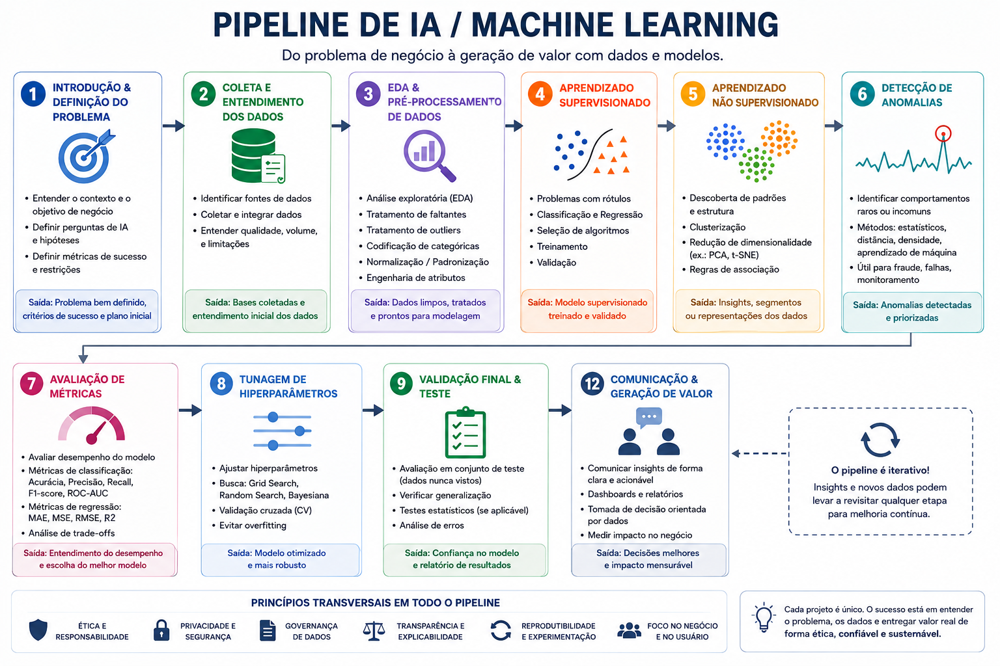

# Aula 3 — Análise Exploratória de Dados (EDA): da Inspeção ao Storytelling
### Pós-graduação em IA Aplicada

**Pré-requisito:** Aula 2 — CRISP-DM: Metodologia, Análise Exploratória e Estatística
**Duração prevista:** ~4h (5 blocos)

---

### O que esta aula cobre

Na Aula 2, vocês tiveram um primeiro contato com CRISP-DM, limpeza básica e alguns gráficos, dentro do contexto das Fases 1–3. Hoje vamos **aprofundar exclusivamente a Fase 2 (Entendimento dos Dados)** — ou seja, vamos abrir a "caixa-preta" da EDA (*Exploratory Data Analysis*) com rigor: como inspecionar, questionar, tratar e comunicar dados **antes** de pensar em qualquer modelo preditivo.

| Bloco | Tema | Duração |
|---|---|---|
| 1 | Introdução, contexto e inspeção estrutural | 45 min |
| 2 | Qualidade dos dados e imputação de faltantes | 50 min |
| 3 | Análise univariada e tratamento de outliers | 50 min |
| 4 | Análise bivariada, multivariada e feature engineering | 50 min |
| 5 | EDA automatizada, storytelling e apresentação | 45 min |

**Fio condutor:** vamos usar, do início ao fim, uma **nova base simulada da mesma cooperativa de crédito** da Aula 2 — mas agora mais rica (com data de adesão, escolaridade, canal de adesão etc.), para termos material suficiente para todos os tópicos de hoje. Os problemas de qualidade (faltantes, duplicatas, outliers) foram novamente inseridos de propósito, e desta vez com **mecanismos de ausência diferentes e documentados** (MCAR, MAR, MNAR) — o que vocês vão precisar identificar, não só corrigir.


## 0. Rápida conexão com a Aula 2

Recapitulando o que já vimos:
- As **6 fases do CRISP-DM**, com foco nas Fases 1–3 (Negócio, Dados, Preparação).
- Duas armadilhas clássicas: **média enganosa por outliers** e **correlação não é causalidade**.
- Limpeza básica: `fillna()` com mediana, `drop_duplicates()`, regra do IQR para outliers.

Hoje continuamos exatamente de onde paramos — mas com uma pergunta mais fina: **antes de simplesmente "limpar", como decidimos, com critério, o que fazer com cada tipo de problema nos dados?** É isso que separa uma EDA superficial de uma EDA que realmente sustenta decisões de negócio.


## 1. Bloco 1 — Introdução, Contexto e Inspeção Estrutural

> 🎯 **Objetivo:** dar o primeiro contato "seguro" com uma base nova — entender sua estrutura, tamanho e tipos de variável antes de qualquer análise.
>
> 📌 **Por que importa:** decisões erradas tomadas aqui (classificar mal um tipo de variável, não notar uma coluna com nome sujo) se propagam por todo o resto da análise.
>
> 💡 **Exemplo:** tratar `n_atrasos_ultimos_12m` (uma contagem) como se fosse contínua levaria a usar um histograma com bins arbitrários, escondendo que ela só assume poucos valores inteiros.

### 1.1 O papel da EDA antes da modelagem preditiva

> 🎯 **Objetivo:** justificar por que se investe tempo em EDA antes de treinar qualquer modelo.
>
> 📌 **Por que importa:** um modelo treinado sobre dados mal compreendidos produz respostas confiantes e erradas — e não avisa que está errado.
>
> 💡 **Exemplo:** se ninguém notasse que 22% de `score_interno` está faltando seguindo um padrão MNAR (Bloco 2), um modelo treinado ingenuamente aprenderia um viés sistemático contra os clientes de score mais alto.

É tentador, principalmente para quem está começando, pular direto para `.fit()` de algum modelo. O problema é que **um modelo treinado em cima de dados mal compreendidos produz respostas confiantes e erradas** — e o modelo não vai te avisar disso.

A EDA (*Exploratory Data Analysis* — Análise Exploratória de Dados) existe para reduzir três riscos, antes de qualquer treinamento:

1. **Risco de dado errado:** valores impossíveis, mal digitados, faltantes que ninguém percebeu.
2. **Risco de pergunta errada:** o modelo até funciona, mas responde algo que não é o que o negócio precisa.
3. **Risco de viés escondido:** desbalanceamento, grupos sub-representados, variáveis que "vazam" a resposta (*data leakage*) — assuntos que vamos aprofundar em aulas futuras, mas que só aparecem se você **olhar** para os dados primeiro.

> 🚩 **Armadilha comum:** tratar a EDA como uma etapa burocrática ("preciso fazer uns gráficos antes de começar de verdade"). Na prática, é comum que **a maior parte dos insights de um projeto de dados venha da EDA**, e não do modelo final.

### 1.2 Formulação de perguntas de negócio antes de abrir o código

> 🎯 **Objetivo:** transformar uma demanda vaga de negócio em uma pergunta que dá para responder com dados.
>
> 📌 **Por que importa:** sem isso, corre-se o risco de produzir uma análise tecnicamente correta que não ajuda ninguém a decidir nada.
>
> 💡 **Exemplo:** "reduzir inadimplência" não é uma pergunta de análise; "quais características dos associados estão associadas a maior risco de atraso?" já é.

Antes de importar qualquer biblioteca, vale a pena escrever, em uma frase:

- **Quem** vai usar essa análise, e para decidir **o quê**?
- Qual é a **unidade de análise**? (um associado, uma transação, um mês?)
- O que seria um resultado **surpreendente o suficiente para virar uma ação**?

Isso evita o erro clássico de produzir 20 gráficos bonitos que não respondem a pergunta de ninguém.

**Contexto de hoje:** a cooperativa de crédito (mesmo cenário da Aula 2) quer entender melhor o **perfil dos associados** e os fatores ligados a **atraso de pagamento**, agora com uma base mais completa — incluindo tempo de relacionamento (via data de adesão), escolaridade e canal pelo qual o associado entrou na cooperativa.

### 1.3 Classificação de variáveis

> 🎯 **Objetivo:** aprender a identificar corretamente o tipo de cada coluna antes de escolher gráfico ou estatística.
>
> 📌 **Por que importa:** o tipo da variável determina literalmente quais ferramentas fazem sentido usar nela — usar a ferramenta errada gera um gráfico enganoso, não só feio.
>
> 💡 **Exemplo:** `escolaridade` (ordinal) pode ser ordenada num boxplot comparativo (Fundamental → Pós-graduação); `canal_adesao` (nominal) não tem uma ordem "certa" para aparecer no eixo de um gráfico.

Toda coluna de uma base de dados pertence a um destes quatro tipos — e o tipo determina **quais gráficos e estatísticas fazem sentido** para ela (é por isso que essa classificação vem antes de qualquer código de EDA):

| Categoria | Subtipo | O que é | Exemplos de hoje |
|---|---|---|---|
| **Qualitativa (categórica)** | Nominal | Categorias sem ordem natural | `canal_adesao` (Agência / App / Indicação) |
| **Qualitativa (categórica)** | Ordinal | Categorias com ordem natural | `escolaridade` (Fundamental < Médio < Superior < Pós-graduação) |
| **Quantitativa (numérica)** | Discreta | Contagem, valores inteiros contáveis | `n_atrasos_ultimos_12m`, `idade` |
| **Quantitativa (numérica)** | Contínua | Pode assumir qualquer valor num intervalo | `renda_mensal`, `score_interno`, `valor_parcela` |

> ⚠️ **Sinalizando incerteza:** essa fronteira nem sempre é perfeita. `idade` é tecnicamente contínua (existe idade em dias/horas), mas quase sempre é tratada como discreta porque medimos em anos inteiros. O importante não é decorar a regra, e sim **justificar a escolha** — o que vocês vão praticar no exercício desta seção.


### Conceito: bibliotecas e `import` (revisão rápida da Aula 2)

> 🎯 **Objetivo:** entender por que Python "sozinho" não faz EDA, e como reaproveitar código pronto de terceiros.
>
> 📌 **Por que importa:** todo o restante do notebook depende dessas bibliotecas — sem entender o `import`, os comandos seguintes parecem "mágica" decorada, não ferramenta compreendida.
>
> 💡 **Exemplo:** sem `import pandas as pd`, o comando `pd.read_csv(...)`, que vamos usar já na próxima seção, simplesmente não existiria para o Python.

Assim como na Aula 2, começamos importando as bibliotecas que vamos reutilizar o tempo todo. `numpy`/`pandas` para dados, `matplotlib`/`seaborn` para gráficos, e agora também `scipy.stats` (medidas estatísticas) e `sklearn.impute` (imputação de faltantes) — que serão usados mais à frente, nos Blocos 2 e 3.


In [2]:
# import numpy: carrega a biblioteca numpy e a apelida de "np"
import numpy as np

# import pandas: carrega a biblioteca pandas e a apelida de "pd"
import pandas as pd

# import matplotlib.pyplot: a "parte de gráficos" do matplotlib, apelidada de "plt"
import matplotlib.pyplot as plt

# import seaborn: biblioteca de gráficos estatísticos construída sobre o matplotlib, apelidada de "sns"
import seaborn as sns

# from scipy import stats: traz funções estatísticas prontas (skew, kurtosis, zscore, testes...)
# vamos usar isso a partir do Bloco 3
from scipy import stats

# configuração só de estética dos gráficos (não afeta os dados, só a aparência)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

print("Bibliotecas carregadas com sucesso.")


Bibliotecas carregadas com sucesso.


### 1.4 Gerando (e depois carregando) a base de hoje

> 🎯 **Objetivo:** simular uma base realista de cooperativa de crédito para praticar em cima dela o dia todo.
>
> 📌 **Por que importa:** em projetos reais vocês raramente vão gerar os dados do zero — mas entender como cada problema foi inserido aqui ajuda a reconhecê-lo depois em dados reais, como no desafio com o HMEQ.
>
> 💡 **Exemplo:** o `pd.read_csv()` que vamos usar na Seção 1.5 é exatamente o mesmo comando que vocês usarão com um arquivo real — só muda o caminho do arquivo.

Em um projeto real, vocês receberiam esse arquivo pronto (de um banco de dados, de um sistema legado, de um export do time de TI). Como não temos acesso à base real da cooperativa, vamos **simular** os dados uma única vez, salvar em CSV, e então fazer exatamente o que vocês fariam com uma base real: **carregar com `pd.read_csv()`**, como pede o roteiro de hoje.

> 📌 **Importante:** o bloco de código abaixo (geração da base sintética) não é o foco pedagógico do Bloco 1 — é só "canalização" para termos uma base realista. O que vocês precisam realmente entender linha a linha começa na Seção 1.5, com `pd.read_csv()`. Se quiserem entender a geração em detalhe, os comentários explicam cada escolha.


In [3]:
# Fixamos a seed para o resultado ser sempre o mesmo para toda a turma
np.random.seed(11)

n = 900  # quantidade de associados fictícios

# ------------------------------------------------------------------
# Identificador (não é uma variável analítica - serve só para simular
# uma chave primária, como em um sistema real)
# ------------------------------------------------------------------
id_associado = np.arange(10001, 10001 + n)

# ------------------------------------------------------------------
# data_adesao: datas de adesão à cooperativa, espalhadas nos últimos ~9 anos
# pd.to_datetime + pd.Timedelta simulam datas aleatórias entre dois limites
# ------------------------------------------------------------------
data_inicio = pd.Timestamp("2016-01-01")
data_fim = pd.Timestamp("2025-12-31")
dias_totais = (data_fim - data_inicio).days
data_adesao = data_inicio + pd.to_timedelta(
    np.random.randint(0, dias_totais, n), unit="D"
)

# ------------------------------------------------------------------
# idade: quantitativa discreta - distribuição normal truncada
# ------------------------------------------------------------------
idade = np.random.normal(42, 12, n).clip(18, 85).round(0)

# ------------------------------------------------------------------
# escolaridade: qualitativa ORDINAL - sorteamos com probabilidades diferentes
# para cada categoria (não uniforme, como costuma ser na vida real)
# ------------------------------------------------------------------
escolaridade = np.random.choice(
    ["Fundamental", "Médio", "Superior", "Pós-graduação"],
    size=n,
    p=[0.15, 0.45, 0.30, 0.10]
)

# ------------------------------------------------------------------
# canal_adesao: qualitativa NOMINAL - não existe ordem entre as categorias
# ------------------------------------------------------------------
canal_adesao = np.random.choice(
    ["Agência", "App", "Indicação"],
    size=n,
    p=[0.5, 0.3, 0.2]
)

# ------------------------------------------------------------------
# renda_mensal: quantitativa contínua, tipicamente assimétrica à direita
# (é assim que renda se comporta no mundo real: poucos valores muito altos)
# ------------------------------------------------------------------
renda_mensal = np.random.lognormal(mean=8.35, sigma=0.45, size=n).clip(1200, 35000)

# ------------------------------------------------------------------
# score_interno: quantitativa contínua (score de crédito interno, 300-850,
# no mesmo espírito de um score de mercado)
# ------------------------------------------------------------------
score_interno = np.random.normal(620, 90, n).clip(300, 850)

# ------------------------------------------------------------------
# n_atrasos_ultimos_12m: quantitativa DISCRETA (contagem) - Poisson é a
# distribuição clássica para "número de eventos raros num período"
# ------------------------------------------------------------------
n_atrasos_ultimos_12m = np.random.poisson(0.6, n)

# ------------------------------------------------------------------
# valor_parcela: quantitativa contínua, calculada a partir da renda
# (parcelas maiores para quem ganha mais, com ruído)
# ------------------------------------------------------------------
valor_parcela = (renda_mensal * np.random.uniform(0.08, 0.25, n)).round(2)

# ------------------------------------------------------------------
# possui_conta_corrente: qualitativa binária
# ------------------------------------------------------------------
possui_conta_corrente = np.random.choice([0, 1], size=n, p=[0.35, 0.65])

print("Variáveis simuladas. Próximo passo: montar o DataFrame.")


Variáveis simuladas. Próximo passo: montar o DataFrame.


In [4]:
# Reunimos tudo em um DataFrame (mesma lógica da Aula 2, Seção 4)
df_bruto = pd.DataFrame({
    "id_associado": id_associado,
    "data_adesao": data_adesao,
    "idade": idade,
    "escolaridade": escolaridade,
    "canal_adesao": canal_adesao,
    "renda_mensal": renda_mensal.round(2),
    "score_interno": score_interno.round(1),
    "n_atrasos_ultimos_12m": n_atrasos_ultimos_12m,
    "valor_parcela": valor_parcela,
    "possui_conta_corrente": possui_conta_corrente,
})

# ------------------------------------------------------------------
# Rótulo de negócio: atrasou_proxima_parcela (para usarmos no Bloco 4)
# Combinamos as variáveis numa "pontuação de risco" e transformamos em
# probabilidade, exatamente como fizemos na Aula 2 (Seção 4, "Gerando o rótulo")
# ------------------------------------------------------------------
pontuacao_risco = (
    0.30
    - 0.00003 * df_bruto["renda_mensal"]
    - 0.0007 * df_bruto["score_interno"]
    + 0.09 * df_bruto["n_atrasos_ultimos_12m"]
)
prob_atraso = 1 / (1 + np.exp(-pontuacao_risco))  # função logística: garante resultado entre 0 e 1
df_bruto["atrasou_proxima_parcela"] = (np.random.rand(n) < prob_atraso).astype(int)

print(f"Base simulada com {df_bruto.shape[0]} linhas e {df_bruto.shape[1]} colunas (ainda sem os problemas de qualidade).")

df_bruto

Base simulada com 900 linhas e 11 colunas (ainda sem os problemas de qualidade).


,id_associado,data_adesao,idade,escolaridade,canal_adesao,renda_mensal,score_interno,n_atrasos_ultimos_12m,valor_parcela,possui_conta_corrente,atrasou_proxima_parcela
0,10001,2021-04-29,58.0,Médio,Agência,7405.59,476.6,1,1595.64,1,1
1,10002,2019-01-09,39.0,Médio,App,3464.39,770.2,0,473.46,1,1
2,10003,2024-08-29,42.0,Médio,Agência,3600.33,580.8,0,854.03,1,0
3,10004,2025-05-02,25.0,Superior,Agência,5075.69,659.1,0,657.41,1,1
4,10005,2019-07-17,29.0,Médio,Agência,4682.47,401.3,0,650.00,1,0
...,...,...,...,...,...,...,...,...,...,...,...
895,10896,2016-08-21,34.0,Médio,App,2355.64,709.4,0,504.24,1,0
896,10897,2017-03-12,39.0,Fundamental,Agência,4839.16,729.9,3,590.23,1,0
897,10898,2020-08-30,72.0,Superior,App,4497.89,573.9,0,843.44,1,0
898,10899,2023-05-24,33.0,Superior,Agência,7845.19,642.6,0,1775.76,0,0


### Inserindo problemas de qualidade — de propósito, e com mecanismos diferentes

> 🎯 **Objetivo:** simular, de propósito, os três mecanismos de ausência (MCAR/MAR/MNAR) e dois erros operacionais comuns, para praticar diagnosticá-los.
>
> 📌 **Por que importa:** no mundo real ninguém rotula os dados como "isto aqui é MNAR" — vocês precisam saber reconhecer o padrão sozinhos, a partir de evidência indireta.
>
> 💡 **Exemplo:** o mesmo raciocínio usado aqui para simular a ausência de `score_interno` é o que vocês vão aplicar, de forma investigativa (sem gabarito pronto), no desafio com o dataset HMEQ.

Diferente da Aula 2 (onde apenas apagamos dados aleatoriamente), avançamos agora para simular **três mecanismos fundamentais de ausência de dados (*missingness*)** — que vocês vão precisar reconhecer na Seção 2.1 — além de **inconsistências operacionais** comuns em ambientes de produção.

#### 1. Mecanismos de Ausência (Missing Data)

**MCAR — *Missing Completely At Random* (coluna `idade`)**
- **Definição:** a probabilidade de o dado faltar é puramente aleatória, independente de qualquer outra variável do dataset.
- **Cenário simulado:** uma falha temporária de infraestrutura (ex.: perda de pacotes numa integração de sistemas). Não introduz viés estatístico — apenas reduz o volume útil de dados.

**MAR — *Missing At Random* (coluna `renda_mensal`)**
- **Definição:** a ausência depende de **outra variável já observada** na base, e não do próprio valor da renda.
- **Cenário simulado:** ocorre com maior frequência em cadastros feitos via App (`canal_adesao`), onde o formulário costuma pular essa etapa. Como a causa está mapeada em outra coluna observada, esse é o caso em que técnicas de **imputação preditiva** (como `KNNImputer` ou regressão) tendem a funcionar melhor do que uma simples média/mediana — vamos comparar as duas abordagens na Seção 2.5.

**MNAR — *Missing Not At Random* (coluna `score_interno`)**
- **Definição:** a probabilidade de omissão depende diretamente do **próprio valor que está faltando**.
- **Cenário simulado:** falta mais para associados com score mais alto. É o caso **mais crítico** em ciência de dados: qualquer substituição simples (média, mediana) altera a distribuição real dos dados e enviesa sistematicamente qualquer análise ou modelo construído em cima dela — como vamos formalizar na Seção 2.2.

#### 2. Inconsistências Operacionais

- **Linhas duplicadas:** simulam falhas de ingestão no pipeline de dados ou duplicação de requisições no front-end (por exemplo, reenvio de um formulário por lentidão de rede).
- **Outliers em `score_interno`:** simulam erros manuais de digitação ou falhas de conversão de escala (aqui, valores multiplicados por 10 por engano) — problemas que não aparecem como faltantes, mas como valores presentes e **implausíveis**. Diferente dos faltantes, esses exigem detecção tanto por **regra de negócio** (o score teórico é limitado a 300–850 — qualquer valor fora disso já é, por definição, um erro) quanto por critérios estatísticos (IQR / Z-Score), que vamos aplicar no Bloco 3.


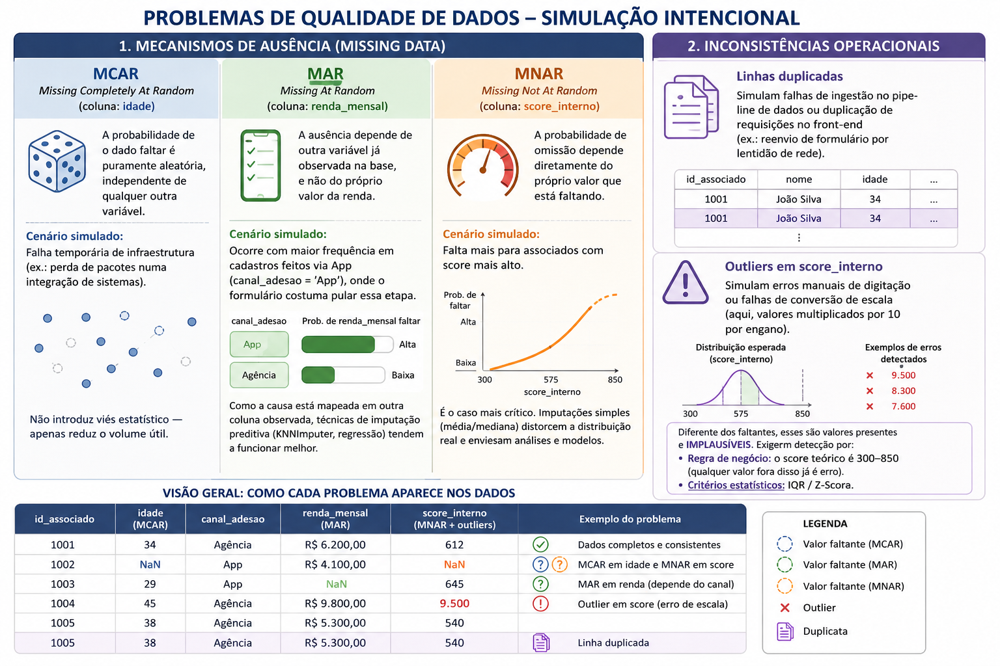

In [5]:
df = df_bruto.copy()

# ------------------------------------------------------------------
# MCAR em "idade": 3% das linhas, sorteadas SEM nenhuma relação com
# outras colunas - simula uma falha de sistema pura
# ------------------------------------------------------------------
idx_mcar = np.random.choice(df.index, size=int(0.03 * n), replace=False)
df.loc[idx_mcar, "idade"] = np.nan

# ------------------------------------------------------------------
# MAR em "renda_mensal": probabilidade de faltar depende do canal de
# adesão (observado) - associados que entraram pelo App têm 25% de
# chance de faltar renda; os demais, só 3%
# ------------------------------------------------------------------
prob_faltar_renda = np.where(df["canal_adesao"] == "App", 0.25, 0.03)
sorteio_renda = np.random.rand(n) < prob_faltar_renda
df.loc[sorteio_renda, "renda_mensal"] = np.nan

# ------------------------------------------------------------------
# MNAR em "score_interno": probabilidade de faltar depende do PRÓPRIO
# valor (não observado) - quanto maior o score, maior a chance de faltar
# Normalizamos o score para uma escala 0-1 só para virar uma probabilidade
# ------------------------------------------------------------------
score_normalizado = (df["score_interno"] - df["score_interno"].min()) / (
    df["score_interno"].max() - df["score_interno"].min()
)
prob_faltar_score = 0.05 + 0.30 * score_normalizado  # de 5% a 35%, conforme o score sobe
sorteio_score = np.random.rand(n) < prob_faltar_score
df.loc[sorteio_score, "score_interno"] = np.nan

# ------------------------------------------------------------------
# Duplicatas: repetimos 18 linhas já existentes (simula erro de cadastro
# em duplicidade)
# ------------------------------------------------------------------
linhas_para_duplicar = df.sample(18, random_state=5)
df = pd.concat([df, linhas_para_duplicar], ignore_index=True)

# ------------------------------------------------------------------
# Outliers de digitação em "score_interno": em 10 linhas, simulamos um
# erro de digitação que multiplica o score por 10 (ex.: 640 virou 6400)
# .dropna() garante que só escolhemos linhas onde o score não é nulo
# ------------------------------------------------------------------
idx_outlier_score = df["score_interno"].dropna().sample(10, random_state=8).index
df.loc[idx_outlier_score, "score_interno"] = df.loc[idx_outlier_score, "score_interno"] * 10

# ------------------------------------------------------------------
# Coerência de nomes de colunas: de propósito, deixamos uma coluna com
# nome "sujo" (maiúscula e espaço), para praticarmos na Seção 1.6
# ------------------------------------------------------------------
df = df.rename(columns={"possui_conta_corrente": "Possui Conta Corrente "})

print(f"Base final com problemas de qualidade: {df.shape[0]} linhas.")


Base final com problemas de qualidade: 918 linhas.


### 1.5 Carregamento via `pd.read_csv()` — o passo que vocês fariam com dados reais

> 🎯 **Objetivo:** praticar o fluxo real de "receber um arquivo e carregá-lo", não só gerar dados na memória.
>
> 📌 **Por que importa:** é o primeiro comando que vocês vão rodar em praticamente qualquer projeto de dados profissional — vale a pena ele estar automático.
>
> 💡 **Exemplo:** trocar `parse_dates=["data_adesao"]` pela lista de colunas de data corretas é o único ajuste necessário para reaproveitar este mesmo comando em qualquer outra base.

Agora sim: salvamos a base em CSV (simulando "o arquivo que o time de TI te mandou") e a carregamos com `pd.read_csv()`, exatamente como vocês fariam com qualquer dataset real.

**Conceito: `pd.read_csv()`**
Lê um arquivo de texto separado por vírgulas (CSV) e devolve um `DataFrame`. Os parâmetros mais usados no dia a dia:
- `sep`: caractere separador (padrão é vírgula; em bases brasileiras é comum ser `;`).
- `decimal`: separador decimal (padrão é `.`; em bases brasileiras é comum ser `,`).
- `encoding`: codificação de caracteres (`"utf-8"` cobre a maioria dos casos; `"latin1"` aparece em exports mais antigos).
- `parse_dates`: lista de colunas para já converter para data no momento da leitura.


In [6]:
# Salva a base simulada em CSV (simulando o "arquivo recebido")
df.to_csv("cooperativa_associados.csv", index=False)

# Carrega de volta com pd.read_csv - este é o comando que vocês usariam
# com qualquer arquivo real de vocês, só trocando o caminho do arquivo
# parse_dates=["data_adesao"] já converte essa coluna para o tipo data na leitura
df = pd.read_csv("cooperativa_associados.csv", parse_dates=["data_adesao"])

print("Base carregada via pd.read_csv(). Vamos auditar o formato a seguir.")


Base carregada via pd.read_csv(). Vamos auditar o formato a seguir.


### 1.6 Auditoria do formato

> 🎯 **Objetivo:** responder, de forma sistemática, "o que é essa base?" antes de qualquer estatística.
>
> 📌 **Por que importa:** pular essa etapa é a causa mais comum de erros bobos (comparar coluna errada, não notar um tipo trocado) que só aparecem várias células depois.
>
> 💡 **Exemplo:** `df.info()` sozinho já revela, de uma vez, se `idade` está com valores faltando e se `data_adesao` foi lida como texto em vez de data.

Antes de qualquer estatística, respondemos perguntas estruturais básicas — que muita gente pula:

- **Quantas linhas e colunas eu tenho?** → `df.shape`
- **Qual o tipo de cada coluna, e faz sentido?** → `df.dtypes`
- **Visão geral (tipos + memória + nulos) de uma vez?** → `df.info()`
- **Os dados "parecem certos" numa espiada rápida?** → `df.head()` / `df.tail()`
- **Os nomes das colunas estão consistentes?** (maiúsculas, espaços, acentos)

**Conceito: `df.dtypes` vs `df.info()`**
`df.dtypes` mostra só o tipo de cada coluna. `df.info()` mostra isso **e também** quantos valores não-nulos existem por coluna e o consumo de memória — é geralmente o primeiro comando que se roda em qualquer dataset novo.


In [7]:
# .shape devolve uma tupla (quantidade_de_linhas, quantidade_de_colunas)
print("Formato (linhas, colunas):", df.shape)


Formato (linhas, colunas): (918, 11)


In [8]:
# .dtypes mostra o tipo de dado que o pandas atribuiu a cada coluna
# "object" costuma indicar texto/categoria; "int64"/"float64" são numéricos;
# "datetime64" é data
print(df.dtypes)


id_associado                        int64
data_adesao                datetime64[ns]
idade                             float64
escolaridade                       object
canal_adesao                       object
renda_mensal                      float64
score_interno                     float64
n_atrasos_ultimos_12m               int64
valor_parcela                     float64
Possui Conta Corrente               int64
atrasou_proxima_parcela             int64
dtype: object


In [9]:
# .info() resume tipos, contagem de não-nulos e memória de uma vez só
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   id_associado             918 non-null    int64         
 1   data_adesao              918 non-null    datetime64[ns]
 2   idade                    889 non-null    float64       
 3   escolaridade             918 non-null    object        
 4   canal_adesao             918 non-null    object        
 5   renda_mensal             833 non-null    float64       
 6   score_interno            715 non-null    float64       
 7   n_atrasos_ultimos_12m    918 non-null    int64         
 8   valor_parcela            918 non-null    float64       
 9   Possui Conta Corrente    918 non-null    int64         
 10  atrasou_proxima_parcela  918 non-null    int64         
dtypes: datetime64[ns](1), float64(4), int64(4), object(2)
memory usage: 79.0+ KB


In [10]:
# .head() mostra as 5 primeiras linhas (padrão) - útil para uma primeira
# checagem visual de "isso parece razoável?"
df.head()


,id_associado,data_adesao,idade,escolaridade,canal_adesao,renda_mensal,score_interno,n_atrasos_ultimos_12m,valor_parcela,Possui Conta Corrente,atrasou_proxima_parcela
0,10001,2021-04-29,58.0,Médio,Agência,7405.59,476.6,1,1595.64,1,1
1,10002,2019-01-09,39.0,Médio,App,3464.39,770.2,0,473.46,1,1
2,10003,2024-08-29,42.0,Médio,Agência,3600.33,NaN,0,854.03,1,0
3,10004,2025-05-02,25.0,Superior,Agência,5075.69,NaN,0,657.41,1,1
4,10005,2019-07-17,29.0,Médio,Agência,4682.47,401.3,0,650.00,1,0


In [11]:
# .tail() mostra as últimas linhas - importante porque bases reais às vezes
# têm lixo de sistema (linhas de rodapé, totais, etc.) só no final do arquivo
df.tail()


,id_associado,data_adesao,idade,escolaridade,canal_adesao,renda_mensal,score_interno,n_atrasos_ultimos_12m,valor_parcela,Possui Conta Corrente,atrasou_proxima_parcela
913,10276,2016-08-21,51.0,Médio,Indicação,4017.08,730.3,2,993.21,1,0
914,10516,2017-03-21,30.0,Superior,Agência,5042.67,700.5,2,617.52,1,0
915,10262,2022-12-10,42.0,Médio,Indicação,4165.76,618.6,0,792.89,1,0
916,10624,2022-09-06,53.0,Superior,Agência,2763.03,NaN,1,450.07,1,0
917,10282,2024-07-05,47.0,Fundamental,Agência,1796.81,535.1,1,341.27,0,0


### Consumo de memória e coerência de nomes de colunas

> 🎯 **Objetivo:** detectar problemas "invisíveis" de higiene de dados que quebram código silenciosamente.
>
> 📌 **Por que importa:** um nome de coluna com espaço ou maiúscula não dá erro na hora — dá erro (ou resultado errado) três células depois, quando já é mais difícil de rastrear a causa.
>
> 💡 **Exemplo:** `"Possui Conta Corrente "` (com espaço no fim) e `"possui_conta_corrente"` seriam tratadas como duas colunas diferentes se alguém tentasse cruzar esta base com outra.

**Conceito: `df.memory_usage(deep=True)`**
Devolve, por coluna, quantos bytes ela ocupa na memória. O parâmetro `deep=True` é importante para colunas de texto (`object`): sem ele, o pandas costuma **subestimar** o tamanho real de colunas de texto.

> ⚠️ **Sinalizando incerteza:** o consumo exato de memória depende da versão do pandas e do sistema operacional — não tratem os números absolutos como uma verdade universal, tratem como **comparação relativa** entre colunas (quais pesam mais).

**Conceito: coerência de nomes de colunas**
Reparem que renomeamos de propósito uma coluna para `"Possui Conta Corrente "` (com maiúsculas, espaços, e até um espaço sobrando no final). Isso é **extremamente comum** em bases reais (exports de Excel, por exemplo) e quebra código depois, silenciosamente — por exemplo, `df["Possui Conta Corrente "]` funciona, mas `df.possui_conta_corrente` (acesso por atributo) já não funcionaria mais.


In [12]:
# memory_usage(deep=True) - consumo de memória real por coluna, em bytes
# .sort_values(ascending=False) ordena da coluna mais pesada para a mais leve
print(df.memory_usage(deep=True).sort_values(ascending=False))


canal_adesao               67534
escolaridade               64473
id_associado                7344
data_adesao                 7344
n_atrasos_ultimos_12m       7344
idade                       7344
renda_mensal                7344
score_interno               7344
Possui Conta Corrente       7344
valor_parcela               7344
atrasou_proxima_parcela     7344
Index                        132
dtype: int64


In [13]:
# Lista os nomes de colunas "como estão" - reparem no problema na última
print(list(df.columns))


['id_associado', 'data_adesao', 'idade', 'escolaridade', 'canal_adesao', 'renda_mensal', 'score_interno', 'n_atrasos_ultimos_12m', 'valor_parcela', 'Possui Conta Corrente ', 'atrasou_proxima_parcela']


In [14]:
# Padronização de nomes de colunas: um padrão comum é tudo minúsculo,
# sem espaço nas pontas, e espaços internos virando underscore "_"
# .str.strip() remove espaços do início/fim do NOME da coluna
# .str.lower() deixa tudo minúsculo
# .str.replace(" ", "_") troca espaços internos por underscore
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print("Nomes de colunas após padronização:")
print(list(df.columns))


Nomes de colunas após padronização:
['id_associado', 'data_adesao', 'idade', 'escolaridade', 'canal_adesao', 'renda_mensal', 'score_interno', 'n_atrasos_ultimos_12m', 'valor_parcela', 'possui_conta_corrente', 'atrasou_proxima_parcela']


**O que aconteceu:** a coluna que era `"Possui Conta Corrente "` virou `"possui_conta_corrente"` — agora consistente com o resto da base. Esse tipo de padronização parece cosmético, mas evita bugs silenciosos (comparações de string que falham por causa de maiúscula/minúscula, por exemplo) em etapas futuras do projeto.

> 🚩 **Armadilha comum:** padronizar nomes de coluna **depois** de já ter escrito bastante código referenciando o nome antigo — isso quebra tudo. Façam essa padronização **assim que carregarem os dados**, antes de mais nada.


## 2. Bloco 2 — Qualidade dos Dados e Imputação de Faltantes

> 🎯 **Objetivo:** transformar "há dados faltando" em uma decisão de tratamento justificada, não automática.
>
> 📌 **Por que importa:** a forma de tratar um faltante muda o resultado de qualquer análise ou modelo construído depois — e o erro raramente aparece como um erro óbvio.
>
> 💡 **Exemplo:** preencher `score_interno` (MNAR) com a mediana simples esconde justamente os clientes de score mais alto, que são os que mais faltam na base.

### 2.1 Mecanismos de ausência: MCAR, MAR e MNAR

> 🎯 **Objetivo:** aprender a classificar POR QUE um dado está faltando, não só constatar que ele está.
>
> 📌 **Por que importa:** a estratégia certa de imputação depende do mecanismo — usar a mesma receita (ex.: sempre a mediana) para os três tipos é um erro comum.
>
> 💡 **Exemplo:** tratar `renda_mensal` (MAR, ligado ao canal de adesão) com uma mediana global ignora que a ausência tem uma causa identificável, que permite uma correção mais precisa (Seção 2.5).

Nem todo "valor faltante" é igual. A forma como um dado falta muda **qual tratamento é apropriado** — tratar todos os casos com a mesma receita (por exemplo, "sempre preencher com a mediana") é um erro comum.

| Mecanismo | Nome completo | O que significa | Exemplo de hoje | Estratégia mais indicada |
|---|---|---|---|---|
| **MCAR** | *Missing Completely At Random* | A ausência não depende de nada — nem de outras colunas, nem do próprio valor | `idade`: falha pontual de infraestrutura | Imputação simples (mediana) é relativamente segura |
| **MAR** | *Missing At Random* | A ausência depende de **outra coluna observada**, mas não do próprio valor faltante | `renda_mensal`: falta mais para quem entrou pelo `canal_adesao == "App"` | Imputação condicionada ao grupo, ou preditiva (`KNNImputer`, regressão) |
| **MNAR** | *Missing Not At Random* | A ausência depende do **próprio valor**, que não temos como observar diretamente | `score_interno`: falta mais justamente para quem tem score mais alto | Nenhuma imputação resolve de verdade — documentar a limitação é parte da entrega |

> 🚩 **Armadilha comum:** confundir MAR com "aleatório e sem problema". MAR **não é aleatório de verdade** — ele é previsível a partir de outras colunas. O nome é enganoso; o importante é a definição, não a palavra "random" dentro dela.

> ⚠️ **Sinalizando incerteza:** na prática, raramente temos como *provar* que um mecanismo é MCAR, MAR ou MNAR com certeza — isso normalmente é uma **hipótese de trabalho**, baseada em conhecimento de negócio e em padrões observados (como vamos fazer a seguir, olhando se a ausência varia por grupo). Tratem a classificação como raciocínio a documentar, não como fato absoluto.

### 2.2 Cuidados com a perda de variância na imputação simples

> 🎯 **Objetivo:** entender o efeito colateral escondido de "só preencher com a média ou a mediana".
>
> 📌 **Por que importa:** imputação simples pode enfraquecer correlações reais e criar uma falsa sensação de precisão na base tratada.
>
> 💡 **Exemplo:** 203 associados (22% da base) receberiam exatamente o mesmo valor de score se a mediana simples fosse usada sem nenhum critério adicional.

Preencher todo valor faltante com a mesma média/mediana parece inofensivo, mas tem um efeito colateral importante: **reduz artificialmente a variância** da coluna (estamos "empilhando" muitos valores exatamente em cima de um só ponto), o que pode:
- Enfraquecer correlações reais que a variável tinha com outras colunas.
- Fazer testes estatísticos parecerem mais "significativos" do que deveriam (a incerteza real da imputação não é propagada).
- No caso do MNAR, **enviesar sistematicamente** a coluna, porque os valores que faltam não são "parecidos com a média" — são sistematicamente diferentes (no nosso caso, os scores mais altos).

### 2.3 Estratégias de tratamento

> 🎯 **Objetivo:** ter um "cardápio" de opções de tratamento e saber quando cada uma se aplica.
>
> 📌 **Por que importa:** escolher a estratégia errada (ex.: excluir linhas quando o mecanismo não é MCAR) introduz viés sistemático na base tratada.
>
> 💡 **Exemplo:** `KNNImputer` é indicado justamente para `renda_mensal` (MAR), porque existe informação em outras colunas que ajuda a estimar melhor o valor faltante — como veremos na Seção 2.5.

| Estratégia | Quando considerar | Cuidado principal |
|---|---|---|
| **Exclusão** (`dropna`) | Poucos faltantes (ex.: <5%) e aparentemente MCAR | Se não for MCAR, remove sistematicamente um tipo de registro |
| **Média/Mediana** | Numérica, MCAR ou MAR leve | Reduz variância; mediana é mais robusta a outliers que média |
| **Moda** | Categórica | Pode inflar artificialmente a categoria mais comum |
| **Categoria explícita** (ex.: `"Não informado"`) | Categórica, quando a própria ausência pode ser informativa | Precisa que o modelo/análise saiba lidar com essa categoria depois |
| **`KNNImputer`** | Quando existe relação entre colunas que ajuda a "adivinhar" o valor | Mais custoso computacionalmente; sensível à escala das variáveis |

> 📌 **Importante:** para o nosso caso de `score_interno` (MNAR), nenhuma dessas estratégias "resolve" o problema de verdade — elas reduzem o dano, mas o ideal seria investigar **por que** o dado não foi coletado (ex.: mudar o processo de coleta). Isso é uma limitação real da imputação, não só um detalhe técnico.


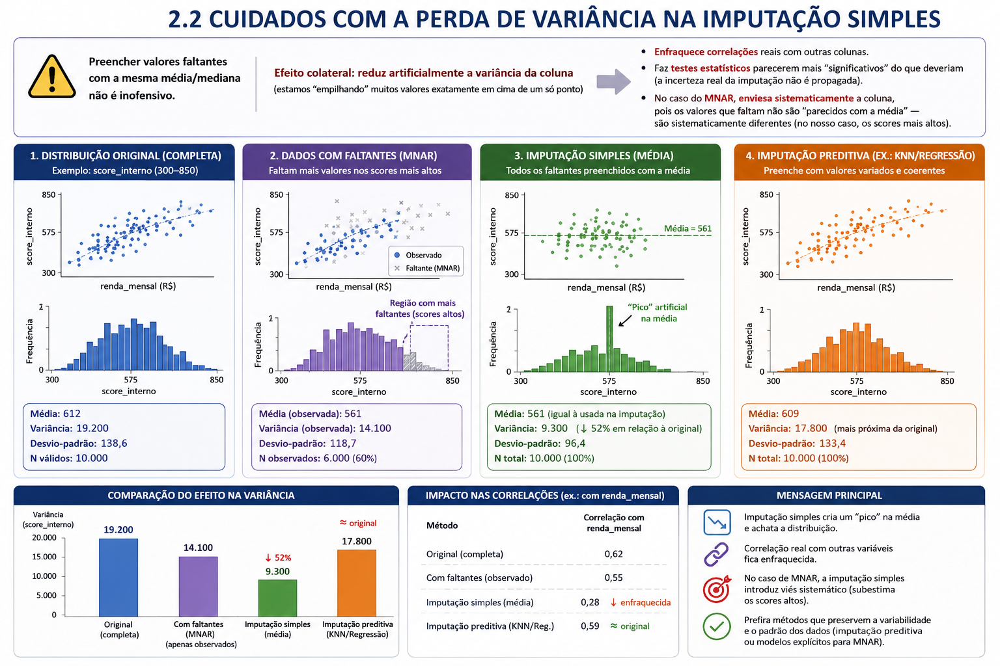

### 2.4 Visualizando faltantes com mapa de calor

> 🎯 **Objetivo:** enxergar visualmente ONDE os faltantes se concentram, antes de qualquer número.
>
> 📌 **Por que importa:** padrões visuais (faltantes concentrados numa faixa de linhas, por exemplo) são pistas de problemas de coleta que uma tabela de números sozinha não evidencia tão bem.
>
> 💡 **Exemplo:** se o mapa de calor mostrasse uma faixa horizontal inteira amarela, isso sugeriria um problema pontual (ex.: um lote de cadastros de um dia específico) — diferente do padrão espalhado que vemos aqui.

**Conceito: `df.isnull()` + `sns.heatmap()`**
`df.isnull()` devolve uma tabela do mesmo tamanho que `df`, só que com `True`/`False` em cada célula. Passar isso direto para `sns.heatmap()` pinta uma cor para `True` (faltante) e outra para `False` — o resultado é um "mapa" visual de onde estão os buracos na base, útil para notar **padrões** (por exemplo, faltantes concentrados em uma faixa de linhas, o que sugeriria um problema de coleta num período específico).


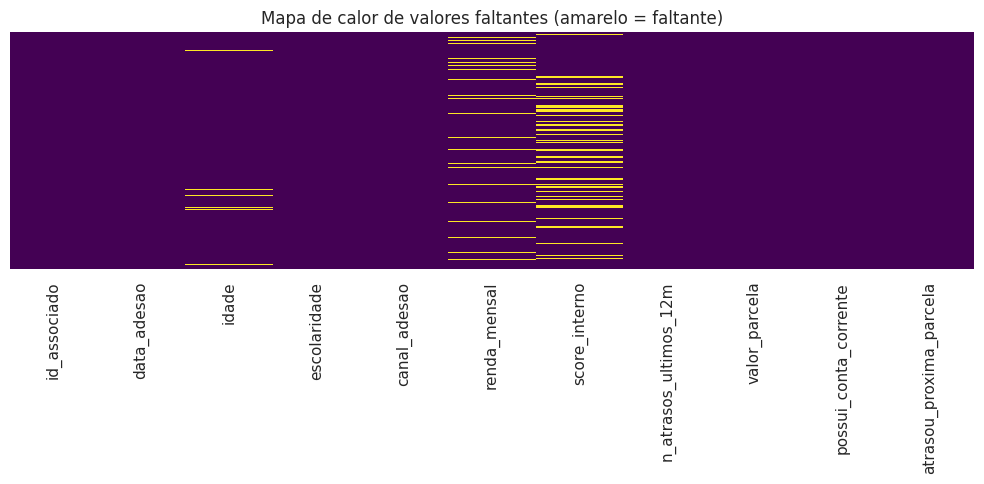

In [15]:
plt.figure(figsize=(10, 5))

# sns.heatmap(df.isnull(), ...) pinta True (faltante) e False (preenchido)
# cbar=False remove a barra de cores lateral (aqui só interessa o padrão visual)
# yticklabels=False esconde os rótulos do eixo Y (900+ linhas não caberiam legíveis)
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")

plt.title("Mapa de calor de valores faltantes (amarelo = faltante)")
plt.tight_layout()
plt.show()


In [16]:
# Contagem objetiva de faltantes por coluna, para complementar o mapa de calor
print("Valores faltantes por coluna:")
print(df.isnull().sum())

print("\nPercentual de faltantes por coluna:")
print((df.isnull().mean() * 100).round(1))


Valores faltantes por coluna:
id_associado                 0
data_adesao                  0
idade                       29
escolaridade                 0
canal_adesao                 0
renda_mensal                85
score_interno              203
n_atrasos_ultimos_12m        0
valor_parcela                0
possui_conta_corrente        0
atrasou_proxima_parcela      0
dtype: int64

Percentual de faltantes por coluna:
id_associado                0.0
data_adesao                 0.0
idade                       3.2
escolaridade                0.0
canal_adesao                0.0
renda_mensal                9.3
score_interno              22.1
n_atrasos_ultimos_12m       0.0
valor_parcela               0.0
possui_conta_corrente       0.0
atrasou_proxima_parcela     0.0
dtype: float64


**Verificando as hipóteses de mecanismo de ausência**

Antes de escolher a estratégia de imputação, vamos checar se as hipóteses da Seção 2.1 se sustentam nos dados — comparando a **taxa de faltantes por grupo**.


In [17]:
# Hipótese MAR: renda_mensal falta mais para quem entrou pelo App?
# .groupby("canal_adesao") separa por canal; ["renda_mensal"].apply(...) calcula
# a proporção de nulos dentro de cada grupo
taxa_faltante_por_canal = df.groupby("canal_adesao")["renda_mensal"].apply(
    lambda coluna: coluna.isnull().mean()
).round(3)

print("Taxa de faltantes em 'renda_mensal', por canal de adesão:")
print(taxa_faltante_por_canal)


Taxa de faltantes em 'renda_mensal', por canal de adesão:
canal_adesao
Agência      0.019
App          0.267
Indicação    0.028
Name: renda_mensal, dtype: float64


In [18]:
# Hipótese MNAR: score_interno falta mais para quem tem score mais alto?
# Como o próprio score é o que falta, não dá pra comparar "score de quem falta"
# diretamente - mas dá pra comparar se OUTRA variável relacionada a score
# (aqui, valor_parcela, que tende a acompanhar o perfil de crédito) difere
# entre quem tem score faltante e quem não tem
media_parcela_score_faltante = df.loc[df["score_interno"].isnull(), "valor_parcela"].mean()
media_parcela_score_presente = df.loc[df["score_interno"].notnull(), "valor_parcela"].mean()

print(f"Valor médio de parcela | score_interno FALTANTE: R$ {media_parcela_score_faltante:,.2f}")
print(f"Valor médio de parcela | score_interno PRESENTE:  R$ {media_parcela_score_presente:,.2f}")


Valor médio de parcela | score_interno FALTANTE: R$ 769.69
Valor médio de parcela | score_interno PRESENTE:  R$ 761.08


> ⚠️ **Sinalizando incerteza:** essa segunda checagem é um indício indireto, não uma prova — estamos usando `valor_parcela` como uma variável "próxima" do score para investigar um padrão que, por definição, não conseguimos observar diretamente (o próprio valor que falta). Se as médias vierem parecidas, isso **não descarta** a hipótese de MNAR — só significa que essa checagem em particular não a confirmou.


### 2.5 Aplicando `fillna()` — mediana para numéricas, moda para categóricas

> 🎯 **Objetivo:** colocar em prática a estratégia de imputação escolhida na Seção 2.3, com um tratamento diferente para cada mecanismo.
>
> 📌 **Por que importa:** é aqui que a teoria vira decisão registrada em código — documentar a escolha (mediana simples vs. mediana por grupo) é o que torna a análise auditável depois.
>
> 💡 **Exemplo:** `renda_mensal` recebe a mediana calculada dentro de cada `canal_adesao`, não uma mediana global — é a diferença entre uma imputação ingênua e uma que respeita o mecanismo MAR identificado.

**Conceito: `.fillna()` e `.mode()`**
`.fillna(valor)` substitui todo `NaN` de uma coluna pelo `valor` informado. Para categóricas, usamos `.mode()[0]` — `.mode()` devolve **todos** os valores mais frequentes (pode haver empate), então pegamos o primeiro com `[0]`.

Seguindo a Seção 2.3, vamos:
- `idade` (MCAR): mediana — mecanismo mais "seguro" para imputação simples.
- `renda_mensal` (MAR): mediana **dentro de cada canal de adesão** (mais preciso do que uma mediana global, já que sabemos que o padrão de ausência varia por canal).
- `score_interno` (MNAR): documentamos a limitação e usamos a mediana mesmo assim, mas destacando que é uma escolha conservadora, não uma solução ideal.


In [19]:
df_imputado = df.copy()

# --- idade (MCAR): mediana simples ---
mediana_idade = df_imputado["idade"].median()
df_imputado["idade"] = df_imputado["idade"].fillna(mediana_idade)

# --- renda_mensal (MAR): mediana POR canal de adesão ---
# .transform("median") calcula a mediana de cada grupo e devolve um valor
# por LINHA (mesmo tamanho da coluna original) - diferente de .median() puro,
# que devolveria só um resumo por grupo
mediana_renda_por_canal = df_imputado.groupby("canal_adesao")["renda_mensal"].transform("median")
df_imputado["renda_mensal"] = df_imputado["renda_mensal"].fillna(mediana_renda_por_canal)

# --- score_interno (MNAR): mediana simples, com a ressalva já documentada acima ---
mediana_score = df_imputado["score_interno"].median()
df_imputado["score_interno"] = df_imputado["score_interno"].fillna(mediana_score)

print("Faltantes após imputação:")
print(df_imputado.isnull().sum())


Faltantes após imputação:
id_associado               0
data_adesao                0
idade                      0
escolaridade               0
canal_adesao               0
renda_mensal               0
score_interno              0
n_atrasos_ultimos_12m      0
valor_parcela              0
possui_conta_corrente      0
atrasou_proxima_parcela    0
dtype: int64


### Comparando com imputação preditiva — `KNNImputer`

> 🎯 **Objetivo:** mostrar, na prática, uma alternativa mais sofisticada à imputação por mediana.
>
> 📌 **Por que importa:** em bases onde existe relação real entre colunas, a imputação preditiva preserva mais variância e captura melhor o perfil de cada registro, em vez de "achatar" todo mundo no mesmo valor.
>
> 💡 **Exemplo:** dois associados do canal App recebem o mesmo valor pela mediana por grupo, mas valores diferentes (e mais plausíveis) pelo `KNNImputer`, conforme o perfil de cada um.

Como registramos na Seção 1.4, `renda_mensal` é um caso de **MAR**: a ausência está ligada a `canal_adesao`, uma coluna observada. Isso abre espaço para uma imputação mais sofisticada do que a mediana por grupo: usar as **outras colunas numéricas do próprio associado** para "adivinhar" a renda mais provável.

**Conceito: `KNNImputer`**
Para cada valor faltante, o `KNNImputer` procura os `n_neighbors` associados mais parecidos (nas colunas que **não** estão faltando) e preenche o valor com a média desses vizinhos — em vez de usar sempre o mesmo número (a mediana) para todo mundo.

**Conceito: `StandardScaler`**
O `KNNImputer` mede "parecença" como distância matemática entre linhas. Sem padronizar antes, uma coluna em escala de milhares (`renda_mensal`) dominaria essa distância só pela magnitude, mesmo que `idade` ou `n_atrasos_ultimos_12m` fossem, na prática, tão relevantes quanto ela. `StandardScaler` resolve isso colocando todas as colunas na mesma escala (média 0, desvio-padrão 1) antes do cálculo, e revertemos a escala original depois com `.inverse_transform()`.


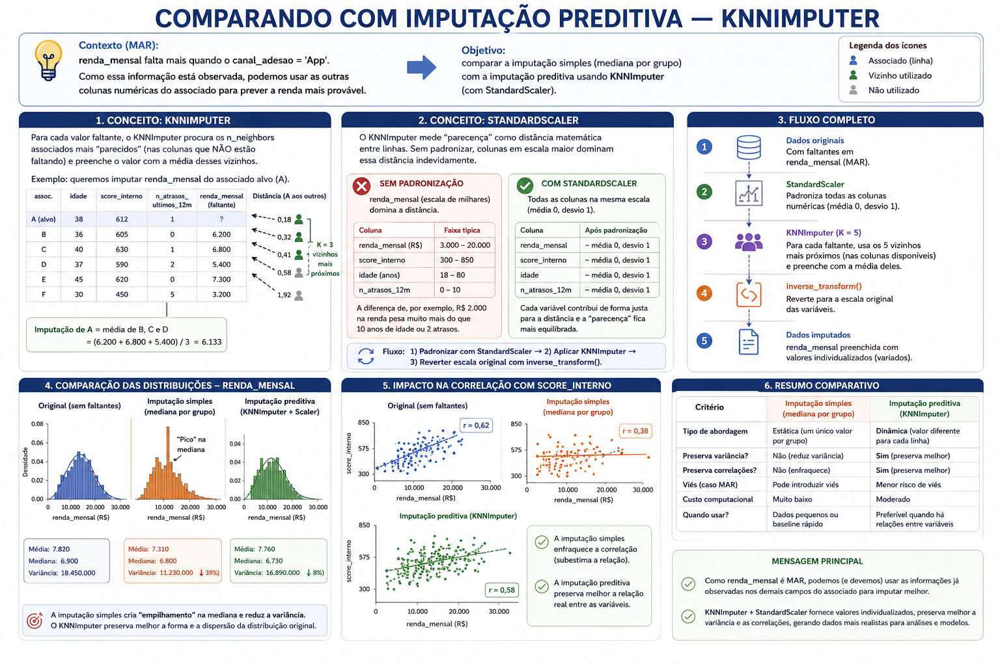

In [20]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

colunas_para_knn = ["idade", "renda_mensal", "score_interno", "n_atrasos_ultimos_12m", "valor_parcela"]

# Padroniza as colunas ANTES de calcular distâncias entre associados
scaler = StandardScaler()
dados_padronizados = scaler.fit_transform(df[colunas_para_knn])

# KNNImputer(n_neighbors=5): imputa usando a média dos 5 vizinhos mais
# próximos - e consegue lidar com várias colunas com faltantes ao mesmo
# tempo (aqui, idade, renda_mensal e score_interno simultaneamente)
knn_imputer = KNNImputer(n_neighbors=5)
dados_imputados_knn = knn_imputer.fit_transform(dados_padronizados)

# Reverte a padronização para voltar à escala original (R$, anos etc.)
dados_imputados_knn = scaler.inverse_transform(dados_imputados_knn)
df_knn = pd.DataFrame(dados_imputados_knn, columns=colunas_para_knn, index=df.index)

# Comparação lado a lado, só nas linhas onde renda_mensal faltava originalmente
linhas_renda_faltante = df["renda_mensal"].isnull()
comparacao_imputacoes = pd.DataFrame({
    "mediana_por_canal": df_imputado.loc[linhas_renda_faltante, "renda_mensal"],
    "knn_imputer": df_knn.loc[linhas_renda_faltante, "renda_mensal"].round(2)
})

display(comparacao_imputacoes.head(10))


,mediana_por_canal,knn_imputer
5,4297.03,8347.00
9,4297.03,3973.44
20,4352.70,5366.92
21,4297.03,4894.87
22,4352.70,9043.14
29,4297.03,5564.92
31,4297.03,4475.27
43,4297.03,6162.33
45,4297.03,7900.50
50,4297.03,2888.92


**O que aconteceu:** a imputação por mediana-por-canal só consegue devolver **3 valores possíveis** (um por `canal_adesao`) — todo associado do App recebe exatamente o mesmo valor. Já o `KNNImputer` devolve um valor **diferente por linha**, calculado a partir do perfil de cada associado (idade, score, valor de parcela...) — preservando mais variância real da coluna, o cuidado que discutimos na Seção 2.2.

> ⚠️ **Sinalizando incerteza:** isso não significa que o `KNNImputer` está "mais certo" — é uma estimativa igualmente sujeita a erro, só que baseada em mais informação. Também é mais caro computacionalmente (escala mal em bases muito grandes) e sensível à escolha de `n_neighbors` e das colunas usadas. Para o restante desta aula, seguimos usando a versão mais simples (`df_imputado`, mediana por canal), por clareza didática — mas em um projeto real, vale comparar as duas antes de decidir.


### 2.6 Remoção de duplicatas e tratamento de strings

> 🎯 **Objetivo:** fechar a limpeza básica, eliminando registros redundantes e inconsistências de digitação.
>
> 📌 **Por que importa:** linhas duplicadas inflam artificialmente contagens e podem distorcer médias, proporções e correlações.
>
> 💡 **Exemplo:** sem `.drop_duplicates()`, as 18 linhas duplicadas inseridas de propósito continuariam contando "duas vezes" no cálculo de qualquer estatística da base.

**Conceito: `.drop_duplicates()`** (revisão da Aula 2) — remove linhas idênticas, mantendo a primeira ocorrência.

**Conceito: `.str.strip()` e `.str.lower()` em VALORES de coluna** (diferente da Seção 1.6, onde aplicamos isso nos **nomes** das colunas — aqui aplicamos no **conteúdo** de uma coluna de texto). É comum bases reais terem `"Superior "`, `"superior"` e `"Superior"` representando a mesma categoria, só por inconsistência de digitação.


In [21]:
linhas_antes = df_imputado.shape[0]
df_imputado = df_imputado.drop_duplicates()
linhas_depois = df_imputado.shape[0]

print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Duplicatas removidas: {linhas_antes - linhas_depois}")


Linhas antes: 918 | Linhas depois: 900 | Duplicatas removidas: 18


In [22]:
# Padronizando a coluna categórica "escolaridade" - mesmo que hoje ela já
# esteja consistente (foi gerada assim), essa é a prática recomendada para
# QUALQUER coluna de texto vinda de fonte externa, então praticamos aqui:
df_imputado["escolaridade"] = df_imputado["escolaridade"].str.strip().str.lower()

# Conferindo as categorias resultantes
print(df_imputado["escolaridade"].value_counts())


escolaridade
médio            408
superior         284
fundamental      119
pós-graduação     89
Name: count, dtype: int64


> 📌 **Importante:** ao deixar `escolaridade` em minúsculas aqui, perdemos a formatação "bonita" (`"Superior"` virou `"superior"`) — isso é aceitável para análise, mas se essa coluna fosse aparecer num relatório final para a diretoria, poderíamos reverter a capitalização só na hora de apresentar (Bloco 5), sem precisar mudar a base de trabalho.


## 3. Bloco 3 — Análise Univariada e Tratamento de Outliers

> 🎯 **Objetivo:** aprender a resumir uma variável com números (não só "olhar" o gráfico) e a tratar valores extremos com critério explícito.
>
> 📌 **Por que importa:** outliers não tratados distorcem médias, correlações e, mais tarde, o próprio treinamento de um modelo.
>
> 💡 **Exemplo:** um único valor de score digitado errado (6.400 em vez de 640) já é suficiente para puxar a média da coluna inteira para cima.

A partir daqui, seguimos trabalhando com `df_imputado` (a base já sem faltantes e sem duplicatas do Bloco 2) — mas **ainda com** os outliers de digitação em `score_interno`, de propósito, para praticar a detecção nesta seção.

### 3.1 Medidas de tendência central e de dispersão

> 🎯 **Objetivo:** relembrar e formalizar as medidas-base de qualquer resumo estatístico.
>
> 📌 **Por que importa:** são o vocabulário mínimo para descrever uma variável numérica de forma precisa e comparável, em vez de impressionista.
>
> 💡 **Exemplo:** dizer "a renda varia bastante" é vago; dizer "o desvio-padrão é de R$ X" é verificável e comparável entre bases diferentes.

**Tendência central** — "para onde os dados tendem a convergir":
- **Média ($\mu$):** soma dividida pela quantidade. Sensível a outliers (Aula 2, Seção 3.1).
- **Mediana:** valor do meio. Robusta a outliers.
- **Moda:** valor(es) mais frequente(s). Só medida "natural" de tendência central para categóricas.

**Dispersão** — "o quanto os dados se espalham":
- **Desvio-padrão ($\sigma$):** o quanto, em média, os valores se afastam da média. Mesma unidade da variável original.
- **Variância:** desvio-padrão ao quadrado. Mesma lógica, mas em unidade "ao quadrado" (menos intuitiva de interpretar sozinha).
- **IQR (intervalo interquartil):** distância entre o 3º quartil (Q3) e o 1º quartil (Q1) — cobre os 50% centrais dos dados. Mais robusto a outliers que o desvio-padrão.

### 3.2 Assimetria (Skewness) e Curtose (Kurtosis)

> 🎯 **Objetivo:** quantificar a FORMA de uma distribuição, além do seu centro e da sua dispersão.
>
> 📌 **Por que importa:** variáveis muito assimétricas (como renda) quebram premissas de várias técnicas estatísticas e merecem um tratamento específico, como veremos na Seção 3.7.
>
> 💡 **Exemplo:** `renda_mensal` com skewness 1,31 confirma numericamente o que o histograma já mostrava: uma cauda longa à direita.

**Skewness (assimetria):** mede se a distribuição "pende" para um lado.
- Skewness ≈ 0: distribuição aproximadamente simétrica.
- Skewness > 0: cauda mais longa à **direita** (valores altos raros puxando a cauda) — típico de variáveis monetárias como `renda_mensal`.
- Skewness < 0: cauda mais longa à **esquerda**.

**Kurtosis (curtose):** mede o quão "pesadas" são as caudas / quão "pontiaguda" é a distribuição, em comparação com uma normal.
- Kurtosis (excesso) ≈ 0: parecida com uma normal em termos de cauda.
- Kurtosis > 0: caudas mais pesadas que a normal (mais valores extremos do que se esperaria).
- Kurtosis < 0: caudas mais leves que a normal.

> ⚠️ **Sinalizando incerteza:** existem diferentes convenções de cálculo de curtose (curtose "crua" vs. "excesso de curtose", que subtrai 3). O `scipy.stats.kurtosis()` usado abaixo já devolve o **excesso de curtose** por padrão (`fisher=True`) — ou seja, 0 já representa "parecido com a normal". Vale conferir a documentação da versão de `scipy` de vocês se esse detalhe for importante para o relatório final.

### 3.3 Critérios numéricos de outliers

> 🎯 **Objetivo:** substituir o "isso parece estranho" por uma regra explícita e reprodutível de detecção de outliers.
>
> 📌 **Por que importa:** sem um critério documentado, duas pessoas diferentes marcariam outliers diferentes na mesma base — o que torna a análise não auditável.
>
> 💡 **Exemplo:** a regra do IQR sinaliza como outlier qualquer score acima de ~778 — um limite calculado a partir dos dados, não escolhido "no olho".

| Critério | Fórmula | Quando usar |
|---|---|---|
| **Regra do IQR** | Abaixo de $Q_1 - 1{,}5 \times IQR$ ou acima de $Q_3 + 1{,}5 \times IQR$ | Não assume distribuição normal; mais robusto |
| **Z-Score** | $\vert Z \vert > 3$, onde $Z = \dfrac{x - \mu}{\sigma}$ | Assume distribuição aproximadamente normal; sensível a outliers no próprio cálculo de $\mu$ e $\sigma$ |

> 🚩 **Armadilha comum:** usar Z-Score em uma variável muito assimétrica (como renda) sem questionar — como o Z-Score usa média e desvio-padrão, que já são sensíveis a outliers, o próprio critério pode ficar distorcido pelos outliers que está tentando detectar. Nesses casos, o IQR costuma ser mais confiável.


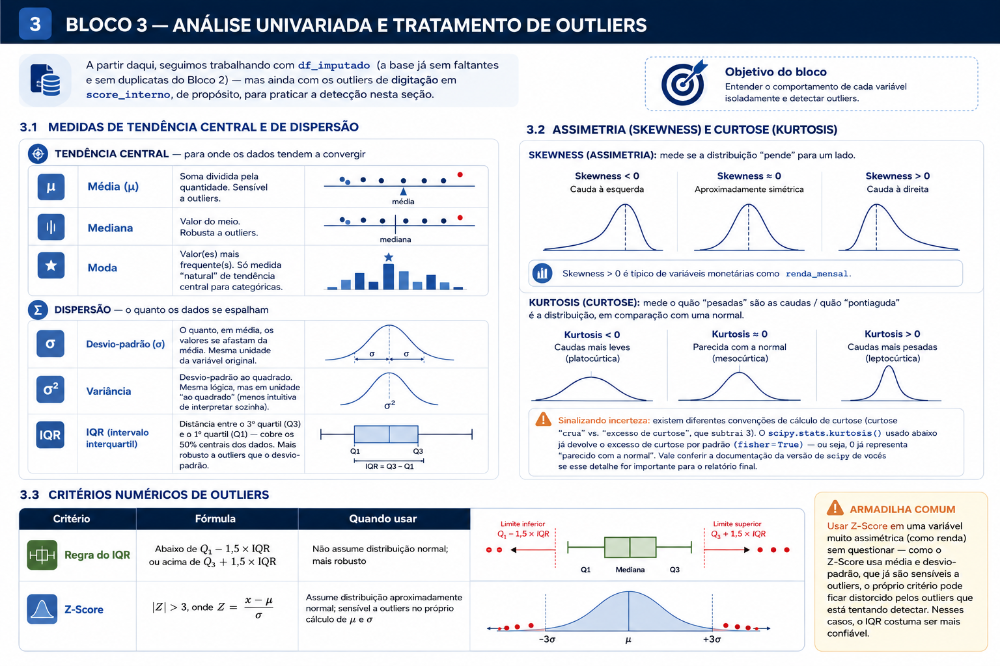

### 3.4 Resumo estatístico com `.describe()`

> 🎯 **Objetivo:** obter, de uma vez, o retrato estatístico de todas as colunas numéricas da base.
>
> 📌 **Por que importa:** costuma ser o primeiro comando a rodar em qualquer coluna nova — economiza escrever várias linhas de código individuais para cada estatística.
>
> 💡 **Exemplo:** reparar que o `max` de `score_interno` está muito acima do percentil 75% já é um primeiro indício de outlier, antes mesmo de qualquer gráfico.



In [23]:
print("Estatísticas descritivas das colunas numéricas:")
display(df_imputado.describe())


Estatísticas descritivas das colunas numéricas:


,id_associado,data_adesao,idade,renda_mensal,score_interno,n_atrasos_ultimos_12m,valor_parcela,possui_conta_corrente,atrasou_proxima_parcela
count,900.000000,900,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000
mean,10450.500000,2020-12-30 16:17:36.000000256,42.157778,4676.820244,673.979889,0.591111,765.859878,0.634444,0.451111
min,10001.000000,2016-01-01 00:00:00,18.000000,1200.000000,357.400000,0.000000,115.560000,0.000000,0.000000
25%,10225.750000,2018-06-17 18:00:00,34.000000,3281.457500,569.900000,0.000000,463.642500,0.000000,0.000000
50%,10450.500000,2020-12-25 12:00:00,42.000000,4297.030000,610.000000,0.000000,669.950000,1.000000,0.000000
75%,10675.250000,2023-07-17 00:00:00,50.000000,5594.847500,653.300000,1.000000,972.455000,1.000000,1.000000
max,10900.000000,2025-12-30 00:00:00,74.000000,14854.190000,7322.000000,5.000000,3151.780000,1.000000,1.000000
std,259.951919,NaN,11.573511,2078.901060,621.302431,0.771812,434.253731,0.481853,0.497881


### 3.5 Visualizando distribuições: histograma + KDE, e boxplot

> 🎯 **Objetivo:** enxergar a forma de uma distribuição, não só seus números-resumo.
>
> 📌 **Por que importa:** duas variáveis podem ter a mesma média e o mesmo desvio-padrão e, ainda assim, ter formatos completamente diferentes.
>
> 💡 **Exemplo:** o boxplot de `score_interno` mostra visualmente os pontos isolados acima do "bigode" — exatamente os outliers de digitação que o `.describe()` só sugeria pelos números.

**Conceito: `sns.histplot(..., kde=True)`**
Além das barras do histograma, o parâmetro `kde=True` sobrepõe uma **curva de densidade estimada** (KDE — *Kernel Density Estimate*), que suaviza o histograma e ajuda a visualizar melhor a forma geral da distribuição (simetria, número de "picos", etc.).


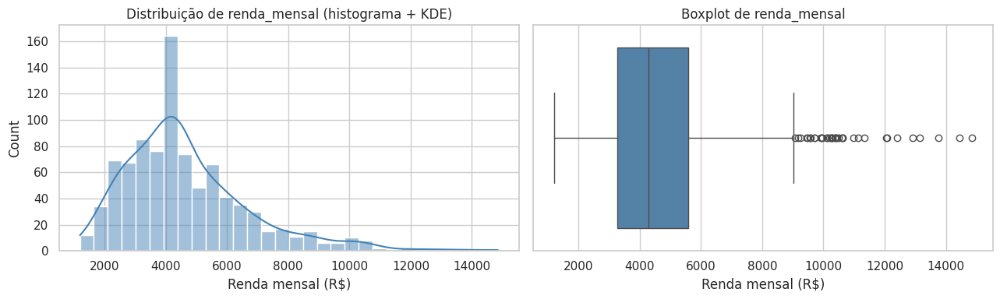

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Histograma + KDE de renda_mensal
sns.histplot(df_imputado["renda_mensal"], bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribuição de renda_mensal (histograma + KDE)")
axes[0].set_xlabel("Renda mensal (R$)")

# Boxplot de renda_mensal
sns.boxplot(x=df_imputado["renda_mensal"], ax=axes[1], color="steelblue")
axes[1].set_title("Boxplot de renda_mensal")
axes[1].set_xlabel("Renda mensal (R$)")

plt.tight_layout()
plt.show()


In [25]:
# Calculando skewness e kurtosis de renda_mensal
skew_renda = stats.skew(df_imputado["renda_mensal"])
kurt_renda = stats.kurtosis(df_imputado["renda_mensal"])  # excesso de curtose (fisher=True, padrão)

print(f"Skewness de renda_mensal: {skew_renda:.2f}")
print(f"Kurtosis (excesso) de renda_mensal: {kurt_renda:.2f}")


Skewness de renda_mensal: 1.31
Kurtosis (excesso) de renda_mensal: 2.45


**Lendo o resultado:** um skewness claramente positivo confirma visualmente o que já esperávamos da Seção 1.4 — `renda_mensal` tem cauda longa à direita. Isso é o gatilho para considerarmos uma **transformação logarítmica** mais adiante (Seção 3.7).

Agora vamos olhar `score_interno`, onde estão os outliers de digitação introduzidos no Bloco 1:


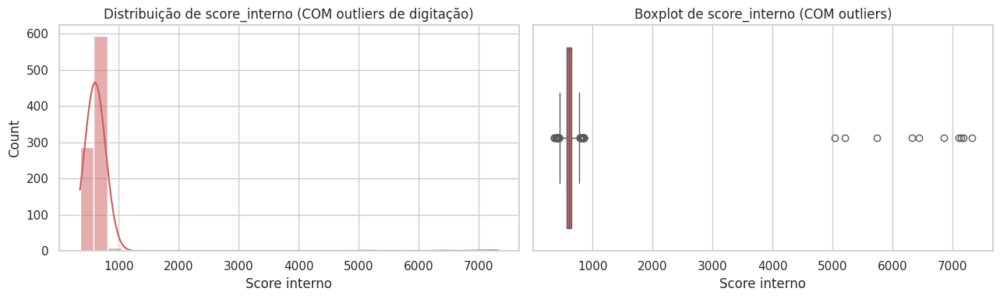

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df_imputado["score_interno"], bins=30, kde=True, ax=axes[0], color="indianred")
axes[0].set_title("Distribuição de score_interno (COM outliers de digitação)")
axes[0].set_xlabel("Score interno")

sns.boxplot(x=df_imputado["score_interno"], ax=axes[1], color="indianred")
axes[1].set_title("Boxplot de score_interno (COM outliers)")
axes[1].set_xlabel("Score interno")

plt.tight_layout()
plt.show()


**O que aconteceu:** alguns poucos valores de `score_interno` estão muito acima de 850 (o teto teórico do score, definido na simulação) — o boxplot mostra claramente esses pontos isolados além do "bigode" superior. Esse é exatamente o padrão visual de um erro de digitação (Seção 3.6 vai calcular os limites formalmente).


### 3.6 Detectando outliers: regra de negócio primeiro, depois critérios estatísticos

> 🎯 **Objetivo:** aplicar, na ordem certa, um critério de negócio barato antes de recorrer a critérios estatísticos mais caros.
>
> 📌 **Por que importa:** nem todo outlier é um erro estatístico — às vezes é simplesmente um valor impossível pela própria definição do produto, e vale a pena checar isso primeiro.
>
> 💡 **Exemplo:** qualquer score acima de 850 já é, por definição, inválido — não precisamos de IQR nem de Z-Score para saber disso.

Antes de qualquer fórmula estatística, vale perguntar: **existe um limite conhecido de negócio para essa variável?** No caso de `score_interno`, sabemos, pela própria definição do produto (Bloco 1), que o score teórico varia entre 300 e 850 — **qualquer valor fora dessa faixa já é, por definição, um erro**, sem precisar de nenhum cálculo estatístico.

Essa checagem é mais barata computacionalmente e mais fácil de explicar para quem não é técnico do que a regra do IQR. Por isso, em ambientes de produção, é comum aplicá-la **primeiro**, como triagem inicial, e só então recorrer a critérios estatísticos (IQR, Z-Score) para os casos mais sutis — onde não existe um limite de negócio tão óbvio (como em `renda_mensal`, que não tem um teto natural evidente).


In [27]:
LIMITE_MINIMO_SCORE = 300
LIMITE_MAXIMO_SCORE = 850

outliers_regra_negocio = df_imputado[
    (df_imputado["score_interno"] < LIMITE_MINIMO_SCORE) |
    (df_imputado["score_interno"] > LIMITE_MAXIMO_SCORE)
]

print(f"Outliers detectados só pela regra de negócio (score fora de {LIMITE_MINIMO_SCORE}-{LIMITE_MAXIMO_SCORE}): {len(outliers_regra_negocio)}")


Outliers detectados só pela regra de negócio (score fora de 300-850): 10


#### Critério estatístico: Regra do IQR

**Conceito: `.quantile()`** (revisão da Aula 2) — `.quantile(0.25)` devolve Q1; `.quantile(0.75)` devolve Q3.


In [28]:
Q1 = df_imputado["score_interno"].quantile(0.25)
Q3 = df_imputado["score_interno"].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f"Q1 = {Q1:.1f} | Q3 = {Q3:.1f} | IQR = {IQR:.1f}")
print(f"Limite inferior = {limite_inferior:.1f} | Limite superior = {limite_superior:.1f}")

# Filtramos as linhas que estão FORA dos limites (outliers, pela regra do IQR)
outliers_iqr = df_imputado[
    (df_imputado["score_interno"] < limite_inferior) |
    (df_imputado["score_interno"] > limite_superior)
]

print(f"\nQuantidade de outliers pela regra do IQR: {len(outliers_iqr)}")


Q1 = 569.9 | Q3 = 653.3 | IQR = 83.4
Limite inferior = 444.8 | Limite superior = 778.4

Quantidade de outliers pela regra do IQR: 53


> 💡 **Comparando os três critérios:** reparem que a quantidade de outliers pela regra de negócio, pela regra do IQR e pelo Z-Score **não precisa bater**. A regra de negócio tende a capturar exatamente os erros de digitação (valores impossíveis); a regra do IQR captura um conjunto mais amplo, que inclui também casos extremos "válidos" da própria distribuição; o Z-Score é o mais sensível à distorção causada pelos próprios outliers extremos (Seção 3.3). Nenhum dos três é "o certo" isoladamente — o ideal é cruzar as três leituras e documentar o critério escolhido.

### Comparando com o critério de Z-Score

> 🎯 **Objetivo:** contrastar um segundo critério estatístico com o resultado do IQR já calculado.
>
> 📌 **Por que importa:** os dois critérios podem discordar, e entender por que ajuda a escolher o mais adequado para cada variável específica.
>
> 💡 **Exemplo:** para `score_interno`, o Z-Score encontrou exatamente os 10 outliers de digitação — o mesmo número que a regra de negócio, mas chegando lá por um caminho estatístico diferente.

**Conceito: `stats.zscore()`**
Calcula, para cada valor de uma coluna, quantos desvios-padrão ele está distante da média. O parâmetro `nan_policy="omit"` faz o cálculo ignorar eventuais `NaN` (não é o caso aqui, já que imputamos no Bloco 2, mas é uma boa prática deixar explícito).


In [29]:
z_scores = stats.zscore(df_imputado["score_interno"], nan_policy="omit")

# np.abs(z_scores) > 3 -> True para cada valor a mais de 3 desvios-padrão da média
outliers_zscore = df_imputado[np.abs(z_scores) > 3]

print(f"Quantidade de outliers pelo critério de Z-Score (|Z| > 3): {len(outliers_zscore)}")


Quantidade de outliers pelo critério de Z-Score (|Z| > 3): 10


> ⚠️ **Sinalizando incerteza:** é esperado que a quantidade de outliers detectados pelos dois critérios **não seja idêntica** — cada um usa uma lógica diferente (quartis vs. média/desvio-padrão), e como vimos no Bloco 3.3, o Z-Score é mais sensível a distorção pelos próprios outliers extremos. Não existe "o critério certo" universal — a escolha depende do contexto e deve ser documentada.


### 3.7 Tratamento: Winsorization e transformação logarítmica

> 🎯 **Objetivo:** aplicar um tratamento aos outliers e à assimetria já identificados, sem simplesmente descartar linhas inteiras.
>
> 📌 **Por que importa:** descartar registros custa informação das outras colunas daquela linha; técnicas como winsorization "domam" o valor extremo sem jogar fora o resto do associado.
>
> 💡 **Exemplo:** depois da winsorization, o score máximo de 7.322 (claramente um erro) passa a ser limitado a um valor plausível, sem excluir esse associado do restante da análise.

**Conceito: Winsorization (truncamento)**
Em vez de **remover** outliers (o que descarta informação das outras colunas daquela linha), a *winsorization* **substitui** valores extremos pelo próprio limite (percentil) definido — "achatando" a cauda sem eliminar a linha.

**Conceito: transformação logarítmica**
$y = \ln(x + 1)$ (o "+1" evita erro matemático quando $x = 0$, já que $\ln(0)$ não existe) comprime valores muito altos proporcionalmente mais do que valores baixos — é uma forma comum de reduzir a assimetria de variáveis como renda, sem alterar a ordem relativa dos dados.


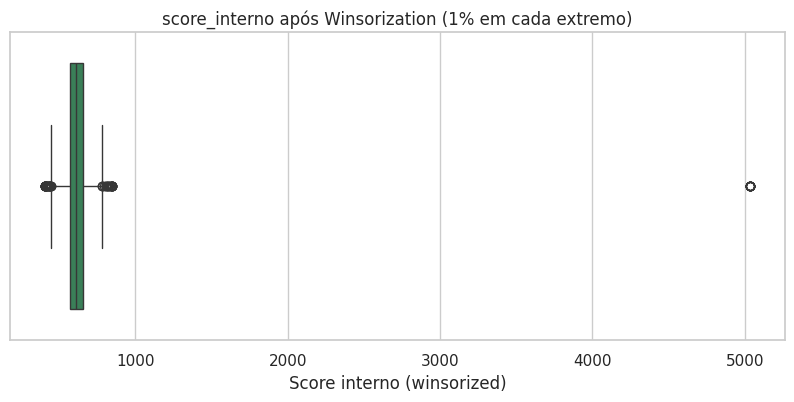

Score máximo ANTES da winsorization: 5033.0
Score máximo DEPOIS da winsorization: 5033.0


In [30]:
from scipy.stats.mstats import winsorize

# winsorize(..., limits=[0.01, 0.01]) substitui o 1% mais baixo e o 1% mais
# alto pelos respectivos valores de percentil 1% e 99% (em vez de removê-los)
score_winsorized = winsorize(df_imputado["score_interno"], limits=[0.01, 0.01])

plt.figure(figsize=(10, 4))
sns.boxplot(x=score_winsorized, color="seagreen")
plt.title("score_interno após Winsorization (1% em cada extremo)")
plt.xlabel("Score interno (winsorized)")
plt.show()

print(f"Score máximo ANTES da winsorization: {df_imputado['score_interno'].max():.1f}")
print(f"Score máximo DEPOIS da winsorization: {np.max(score_winsorized):.1f}")


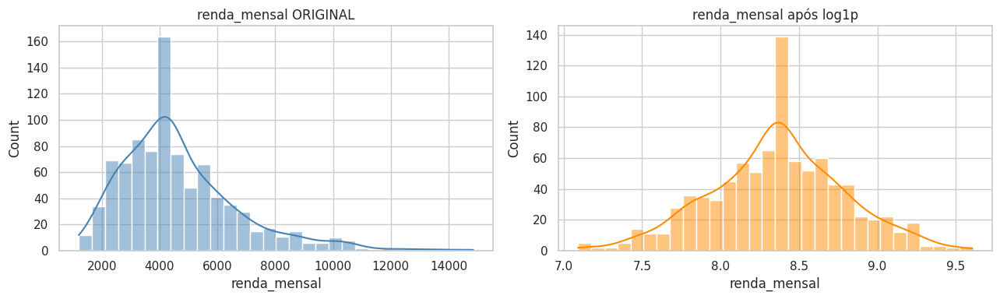

Skewness ANTES do log: 1.31
Skewness DEPOIS do log: -0.06


In [31]:
# Transformação logarítmica em renda_mensal (variável assimétrica, Seção 3.5)
# np.log1p(x) calcula ln(x + 1) diretamente - mais estável numericamente que
# escrever np.log(x + 1) manualmente
renda_log = np.log1p(df_imputado["renda_mensal"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df_imputado["renda_mensal"], bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("renda_mensal ORIGINAL")

sns.histplot(renda_log, bins=30, kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("renda_mensal após log1p")

plt.tight_layout()
plt.show()

print(f"Skewness ANTES do log: {stats.skew(df_imputado['renda_mensal']):.2f}")
print(f"Skewness DEPOIS do log: {stats.skew(renda_log):.2f}")


**O que aconteceu:** a distribuição pós-log fica visivelmente mais próxima de uma forma simétrica (skewness mais perto de 0). Isso é útil sobretudo para técnicas estatísticas/modelos que funcionam melhor com variáveis aproximadamente normais — assunto que retomaremos quando chegarmos à fase de modelagem.

> 📌 **Importante:** transformar uma variável (winsorization, log) muda a **escala** em que ela é lida — um coeficiente ou uma média calculados sobre `renda_log` não têm a mesma interpretação direta em reais (R$) que teriam sobre `renda_mensal` original. Ao apresentar para a diretoria (Bloco 5), é comum reverter a transformação para comunicar em unidades que façam sentido para quem não é técnico.


> 💡 **Dica de conferência:** o resultado de vocês deve ser plausível para uma variável assimétrica como renda — normalmente **maior que zero**, já que a cauda direita longa naturalmente empurra alguns valores para além do limite superior do IQR, mesmo sem nenhum erro de digitação. Isso é diferente do caso de `score_interno`, onde os outliers eram genuinamente erros.


## 4. Bloco 4 — Análise Bivariada, Multivariada e Feature Engineering

> 🎯 **Objetivo:** sair da análise "coluna por coluna" e passar a investigar como as variáveis se relacionam entre si.
>
> 📌 **Por que importa:** é aqui que aparecem os primeiros indícios reais de quais fatores podem estar associados ao risco de atraso — a informação que a diretoria efetivamente quer.
>
> 💡 **Exemplo:** renda e valor de parcela sozinhas dizem pouco sobre risco; a relação ENTRE as duas (Seção 4.1) já começa a contar uma história mais útil.

Para o restante da aula, vamos consolidar o tratamento de outliers de `score_interno` (aplicando a winsorization da Seção 3.7 direto na base) e seguir com essa versão tratada.


In [32]:
df_tratado = df_imputado.copy()
df_tratado["score_interno"] = winsorize(df_tratado["score_interno"], limits=[0.01, 0.01])

print("Base consolidada para o Bloco 4:", df_tratado.shape)


Base consolidada para o Bloco 4: (900, 11)


### 4.1 Relação entre numéricas: Pearson vs. Spearman

> 🎯 **Objetivo:** medir o quanto duas variáveis numéricas "andam juntas", com duas lentes diferentes (linear e monotônica).
>
> 📌 **Por que importa:** usar só Pearson pode esconder relações reais que não são lineares, mas ainda assim são monotônicas.
>
> 💡 **Exemplo:** `renda_mensal` e `valor_parcela` têm correlação de Pearson 0,79 e de Spearman 0,77 — próximas aqui, mas isso nem sempre acontece.

**Correlação de Pearson ($r$):** mede associação **linear** entre duas variáveis numéricas, de -1 a +1. Sensível a outliers e assume que a relação (se existir) é aproximadamente uma reta.

**Correlação de Spearman ($\rho$):** mede associação **monotônica** (quando uma sobe, a outra tende a subir/descer, não necessariamente numa reta) — calculada sobre os **postos (rankings)** dos valores, não sobre os valores brutos. Por isso, é mais robusta a outliers e capta relações não-lineares (desde que monotônicas).

> ⚠️ **Sinalizando incerteza:** nem Pearson nem Spearman captam relações **não-monotônicas** (por exemplo, um "U" — a variável primeiro cai, depois sobe). Um coeficiente de correlação perto de 0, nesses casos, **não significa ausência de relação** — só significa ausência de relação linear/monotônica. Vale sempre olhar o gráfico de dispersão, não só o número.


In [33]:
colunas_numericas = ["idade", "renda_mensal", "score_interno", "n_atrasos_ultimos_12m", "valor_parcela"]

corr_pearson = df_tratado[colunas_numericas].corr(method="pearson")
corr_spearman = df_tratado[colunas_numericas].corr(method="spearman")

print("Correlação de Pearson (renda_mensal x valor_parcela):", round(corr_pearson.loc["renda_mensal", "valor_parcela"], 3))
print("Correlação de Spearman (renda_mensal x valor_parcela):", round(corr_spearman.loc["renda_mensal", "valor_parcela"], 3))


Correlação de Pearson (renda_mensal x valor_parcela): 0.792
Correlação de Spearman (renda_mensal x valor_parcela): 0.769


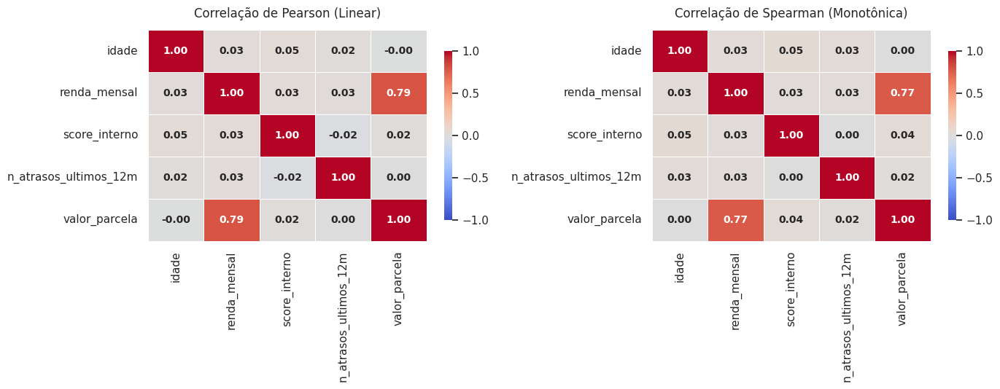

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

# Criando a figura para exibir as duas matrizes lado a lado
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Heatmap - Pearson
sns.heatmap(
    corr_pearson,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    ax=axes[0],
    cbar_kws={"shrink": 0.8},
    annot_kws={"size": 10, "weight": "bold"},
)
axes[0].set_title("Correlação de Pearson (Linear)", fontsize=12, pad=12)

# Heatmap - Spearman
sns.heatmap(
    corr_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    ax=axes[1],
    cbar_kws={"shrink": 0.8},
    annot_kws={"size": 10, "weight": "bold"},
)
axes[1].set_title("Correlação de Spearman (Monotônica)", fontsize=12, pad=12)

plt.tight_layout()
plt.show()

### 4.2 Relação numérica vs. categórica: boxplots comparativos e violin plots

> 🎯 **Objetivo:** comparar a distribuição de uma variável numérica entre diferentes categorias.
>
> 📌 **Por que importa:** correlação (Seção 4.1) só existe entre duas variáveis numéricas — para cruzar numérica com categórica, precisamos de outra ferramenta.
>
> 💡 **Exemplo:** comparar a renda entre os quatro níveis de escolaridade revela se existe um gradiente — algo que uma correlação simples não conseguiria calcular.

**Conceito: Violin Plot**
Combina a ideia do boxplot (quartis, mediana) com uma curva de densidade (como o KDE da Seção 3.5), espelhada dos dois lados — mostra tanto o resumo estatístico quanto a **forma** da distribuição em cada categoria, de uma vez.


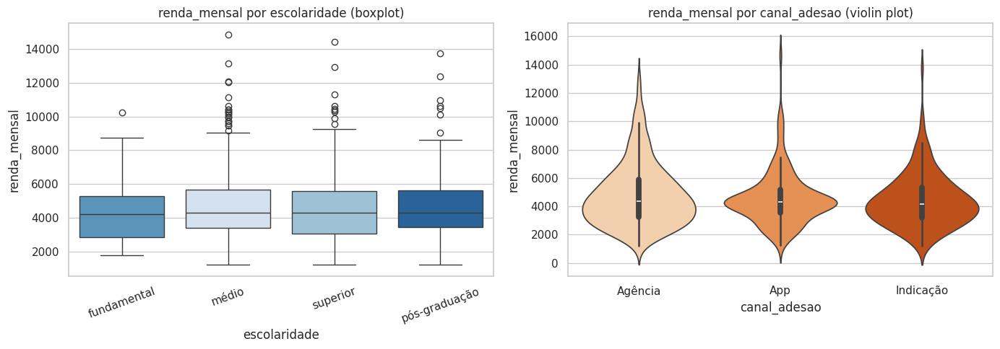

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot: renda_mensal por escolaridade (categórica ORDINAL)
# hue=x + legend=False é a forma recomendada nas versões recentes do seaborn
# para colorir por categoria sem gerar uma legenda redundante
ordem_escolaridade = ["fundamental", "médio", "superior", "pós-graduação"]
sns.boxplot(
    data=df_tratado, x="escolaridade", y="renda_mensal",
    order=ordem_escolaridade, hue="escolaridade", legend=False,
    ax=axes[0], palette="Blues"
)
axes[0].set_title("renda_mensal por escolaridade (boxplot)")
axes[0].tick_params(axis="x", rotation=20)

# Violin plot: renda_mensal por canal_adesao (categórica NOMINAL)
sns.violinplot(
    data=df_tratado, x="canal_adesao", y="renda_mensal",
    hue="canal_adesao", legend=False,
    ax=axes[1], palette="Oranges"
)
axes[1].set_title("renda_mensal por canal_adesao (violin plot)")

plt.tight_layout()
plt.show()


### 4.3 Relação entre categóricas: tabela de contingência e teste $\chi^2$

> 🎯 **Objetivo:** investigar associação entre duas variáveis categóricas, sem depender de correlação (que exige números).
>
> 📌 **Por que importa:** muita informação de negócio mora em colunas categóricas (canal, motivo, profissão) — ignorar essas relações deixa insights na mesa.
>
> 💡 **Exemplo:** cruzar escolaridade com canal de adesão pode revelar, por exemplo, se o público do App tem um perfil educacional diferente do público de agência.

**Conceito: `pd.crosstab()`**
Monta uma tabela de dupla entrada, contando quantas linhas caem em cada combinação de categorias de duas colunas — a base para investigar se duas variáveis categóricas parecem associadas.

**Conceito: teste do $\chi^2$ (qui-quadrado) de independência**
Testa a hipótese de que duas variáveis categóricas são **independentes** (não associadas). `stats.chi2_contingency(tabela)` devolve, entre outros valores, um **p-valor**: convencionalmente, p-valor baixo (< 0,05) é interpretado como evidência **contra** a independência (ou seja, indício de associação).


In [36]:
tabela_contingencia = pd.crosstab(df_tratado["escolaridade"], df_tratado["canal_adesao"])
print("Tabela de contingência (escolaridade x canal_adesao):")
display(tabela_contingencia)

# stats.chi2_contingency devolve: estatística qui-quadrado, p-valor, graus de liberdade, valores esperados
chi2, p_valor, graus_liberdade, valores_esperados = stats.chi2_contingency(tabela_contingencia)

print(f"\nEstatística qui-quadrado: {chi2:.2f}")
print(f"p-valor: {p_valor:.4f}")


Tabela de contingência (escolaridade x canal_adesao):


canal_adesao,Agência,App,Indicação
escolaridade,,,
fundamental,59,30,30
médio,213,120,75
pós-graduação,45,24,20
superior,144,91,49



Estatística qui-quadrado: 5.13
p-valor: 0.5274


> ⚠️ **Sinalizando incerteza:** um p-valor baixo indica associação estatística, **não** o tamanho ou a relevância prática dessa associação — com uma amostra grande, até associações pequenas podem dar p-valor baixo. E, como sempre (Aula 2, Seção 3.2): associação não é causalidade.


### 4.4 Mapa de calor de correlação (multivariada)

> 🎯 **Objetivo:** ver, de uma vez, todas as correlações entre pares de variáveis numéricas.
>
> 📌 **Por que importa:** é o jeito mais rápido de identificar candidatas a "variável mais associada ao risco" antes de qualquer modelagem futura.
>
> 💡 **Exemplo:** procurar, na linha/coluna de `atrasou_proxima_parcela`, qual variável tem a cor mais "quente" (correlação mais forte) é o primeiro passo de qualquer investigação de risco.



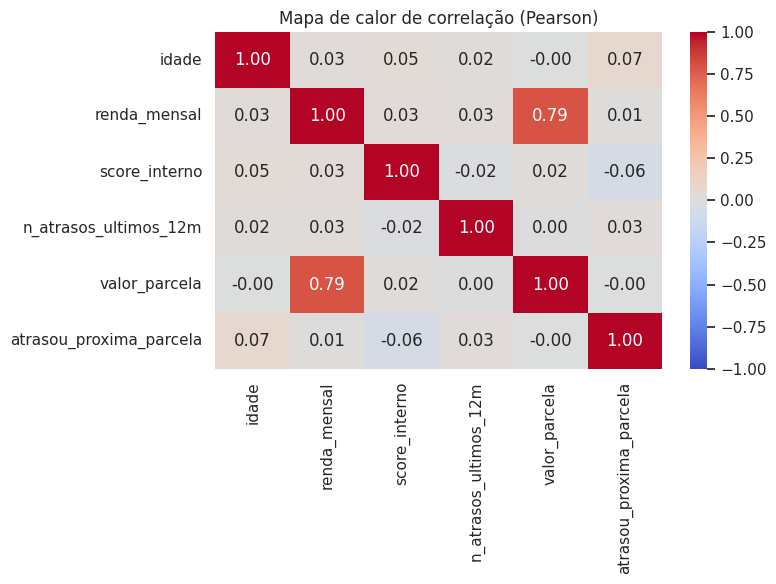

In [37]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df_tratado[colunas_numericas + ["atrasou_proxima_parcela"]].corr(numeric_only=True),
    annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1
)
plt.title("Mapa de calor de correlação (Pearson)")
plt.tight_layout()
plt.show()


**Lendo o mapa de calor:** procurem, na linha/coluna de `atrasou_proxima_parcela`, quais variáveis têm correlação mais forte com o atraso — isso vai ser retomado no exercício desta seção.

### 4.5 Feature Engineering: bins com `pd.cut()` e extração de componentes de data

> 🎯 **Objetivo:** criar novas colunas a partir das existentes, que carreguem mais informação útil para a análise (ou, no futuro, para um modelo).
>
> 📌 **Por que importa:** às vezes a variável mais preditiva ainda não existe na base — ela precisa ser construída a partir do que já temos.
>
> 💡 **Exemplo:** `tempo_como_associado_anos`, calculado a partir de `data_adesao`, pode ser mais informativo para o risco do que a data bruta de adesão.

**Conceito: `pd.cut()`**
Transforma uma variável numérica contínua em **faixas (bins)** categóricas ordinais — útil tanto para visualização quanto porque algumas análises/modelos se beneficiam de variáveis categorizadas.

**Conceito: acessor `.dt`**
Para colunas do tipo `datetime`, o acessor `.dt` dá acesso a componentes como `.dt.year`, `.dt.month`, além de permitir subtrações entre datas (que resultam em `Timedelta`, convertível para dias/anos).


In [38]:
# pd.cut com bins definidos manualmente e rótulos legíveis
# (os limites foram escolhidos olhando o .describe() da Seção 3.4, para que
# nenhuma faixa fique vazia - vale sempre conferir a distribuição real antes
# de "chutar" os limites de um pd.cut)
df_tratado["faixa_renda"] = pd.cut(
    df_tratado["renda_mensal"],
    bins=[0, 2500, 4000, 6000, 9000, np.inf],
    labels=["até 2.5k", "2.5k-4k", "4k-6k", "6k-9k", "acima de 9k"]
)

print(df_tratado["faixa_renda"].value_counts().sort_index())


faixa_renda
até 2.5k       101
2.5k-4k        254
4k-6k          363
6k-9k          142
acima de 9k     40
Name: count, dtype: int64


In [39]:
# Extraindo componentes de data_adesao
df_tratado["ano_adesao"] = df_tratado["data_adesao"].dt.year
df_tratado["mes_adesao"] = df_tratado["data_adesao"].dt.month

# tempo_como_associado_anos: diferença entre hoje e a data de adesão, em anos
# pd.Timestamp.now() pega a data/hora atual; a subtração de datas gera um
# Timedelta, cujo atributo .days dá a diferença em dias - dividimos por 365.25
# para aproximar anos (incluindo anos bissextos)
df_tratado["tempo_como_associado_anos"] = (
    (pd.Timestamp.now() - df_tratado["data_adesao"]).dt.days / 365.25
).round(1)

df_tratado[["data_adesao", "ano_adesao", "mes_adesao", "tempo_como_associado_anos"]].head()


,data_adesao,ano_adesao,mes_adesao,tempo_como_associado_anos
0,2021-04-29,2021,4,5.3
1,2019-01-09,2019,1,7.7
2,2024-08-29,2024,8,2.0
3,2025-05-02,2025,5,1.3
4,2019-07-17,2019,7,7.1


> 📌 **Importante:** `pd.Timestamp.now()` usa a data em que o notebook está rodando — ou seja, `tempo_como_associado_anos` **muda dependendo de quando vocês executarem esta célula**. Isso é aceitável para fins didáticos, mas em um projeto real, esse tipo de "dependência do momento de execução" precisa ser documentado (ou fixado numa data de referência), para os resultados serem reprodutíveis.


> 💡 **Dica de leitura do gráfico:** como `atrasou_proxima_parcela` só assume 0 ou 1, o *scatter plot* vai aparecer como duas "faixas horizontais" de pontos (uma em y=0, outra em y=1) — é normal, e é uma limitação conhecida de scatter plots contra variáveis binárias. Para esse tipo de comparação, um boxplot da variável numérica **separado por grupo** (0 vs. 1), como fizemos na Aula 2 com `.groupby()`, costuma comunicar melhor do que o scatter puro — fica como reflexão para o Bloco 5.


## 5. Bloco 5 — EDA Automatizada, Storytelling e Apresentação

> 🎯 **Objetivo:** fechar o ciclo, comparando a EDA manual com uma automatizada, e transformando achados técnicos em comunicação para a diretoria.
>
> 📌 **Por que importa:** uma EDA que não termina em uma decisão ou recomendação de negócio não gerou valor, mesmo que esteja tecnicamente correta.
>
> 💡 **Exemplo:** descobrir que `renda_mensal` falta mais no canal App só vira valor de negócio quando alguém recomenda "tornar o campo obrigatório no formulário do App".

### 5.1 Ferramentas de profiling automático e seus limites

> 🎯 **Objetivo:** conhecer atalhos que aceleram a primeira triagem de uma base nova.
>
> 📌 **Por que importa:** usadas sem crítica, essas ferramentas dão uma falsa sensação de "já fiz a EDA completa" — sem substituir o raciocínio de negócio dos blocos anteriores.
>
> 💡 **Exemplo:** um relatório automático aponta que `renda_mensal` é assimétrica, mas não sabe (nem pode saber) que decidimos tratar isso com `log1p` por causa da Seção 3.7.

Existem bibliotecas que geram, com uma ou duas linhas de código, um relatório completo de EDA: estatísticas descritivas, histogramas, matriz de correlação, contagem de faltantes, tudo de uma vez. As mais conhecidas são `ydata-profiling` (antigo `pandas-profiling`) e `sweetviz`.

**Vantagens:**
- Extremamente rápido para uma primeira visão geral.
- Bom para não deixar passar nada óbvio (ex.: uma coluna 100% nula que ninguém notou).

**Limites:**
- **Não substitui o raciocínio de negócio** dos Blocos 1-4 — o relatório não sabe qual é a pergunta que a cooperativa está tentando responder.
- Pode ficar lento/pesado em bases muito grandes (o relatório calcula praticamente tudo contra tudo).
- Gráficos genéricos, sem o contexto e as decisões documentadas que fizemos manualmente (por que winsorizar, por que a mediana e não a média, etc.).

> ⚠️ **Sinalizando incerteza:** essas bibliotecas não vêm pré-instaladas por padrão em todo ambiente Colab, e suas APIs mudam entre versões com alguma frequência. O código abaixo está escrito com `try/except` propositalmente — se algum comando específico (`.to_notebook_iframe()`, por exemplo) tiver mudado na versão que o Colab instalar para vocês, verifiquem a documentação oficial da biblioteca antes de assumir que o código está errado.

### 5.2 Prática Guiada — Executando e comparando com a análise manual

> 🎯 **Objetivo:** rodar, na prática, duas ferramentas de profiling automático sobre a base já tratada.
>
> 📌 **Por que importa:** comparar lado a lado com a análise manual é o que evidencia o que a automação entrega bem e o que ela não substitui.
>
> 💡 **Exemplo:** o relatório do `ydata-profiling` provavelmente re-descobre a assimetria de `renda_mensal` em segundos — mas não sabe explicar por que decidimos winsorizar `score_interno` em vez de excluí-lo.



In [40]:
# Instalação (Colab não traz essas bibliotecas por padrão, normalmente)
# O "!" no início executa um comando de terminal dentro do notebook
!pip install -q ydata-profiling sweetviz


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.1/15.1 MB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 84.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 35.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 4.7 MB/s eta 0:00:00


In [41]:
# ydata-profiling: gera um relatório completo em HTML/iframe
try:
    from ydata_profiling import ProfileReport

    perfil = ProfileReport(
        df_tratado,
        title="Relatório Automático - Cooperativa de Crédito (Aula 3)",
        minimal=True,  # minimal=True acelera a geração, reduzindo algumas análises mais pesadas
    )

    # No Colab, .to_notebook_iframe() exibe o relatório embutido na própria célula
    perfil.to_notebook_iframe()

except Exception as erro:
    print("Não foi possível gerar o relatório com ydata-profiling nesta sessão.")
    print("Detalhe do erro (útil para debug):", erro)
    print("Verifiquem a instalação/versão da biblioteca em https://docs.profiling.ydata.ai/")


/tmp/ipykernel_2051/3612650073.py:3: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 15/15 [00:00<00:00, 43.34it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

                                             |          | [  0%]   00:00 -> (? left)

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:4809: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(



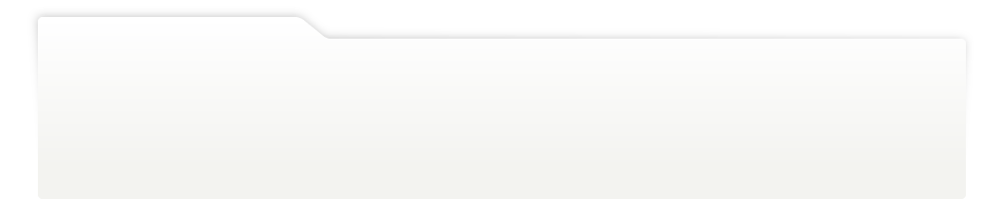
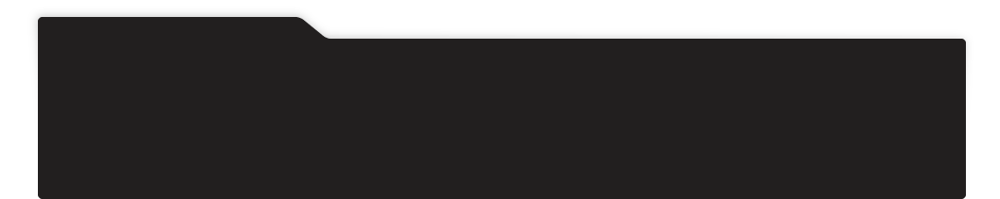
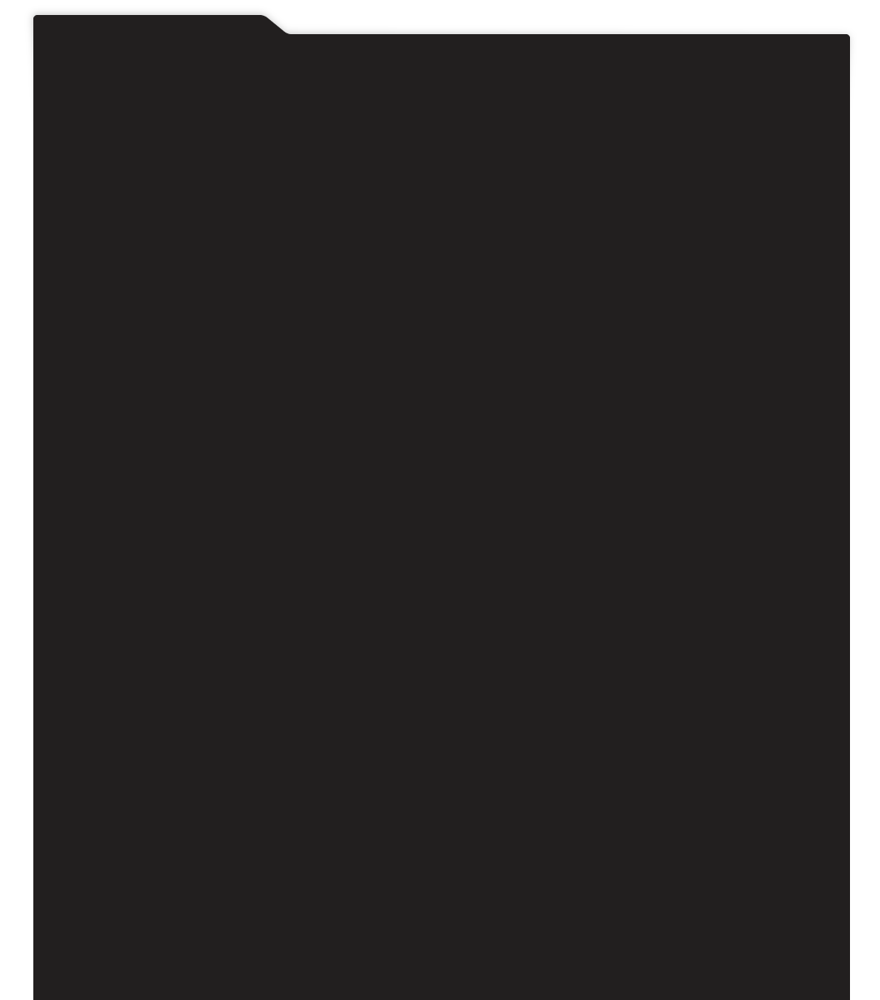
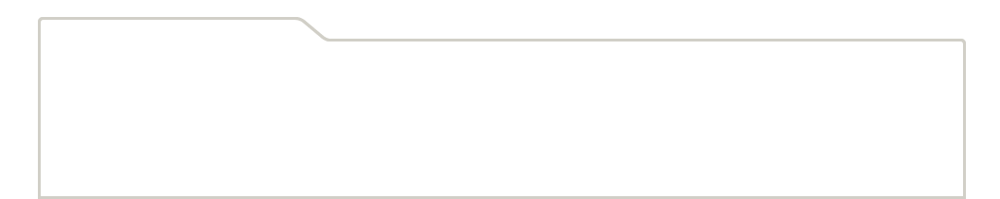
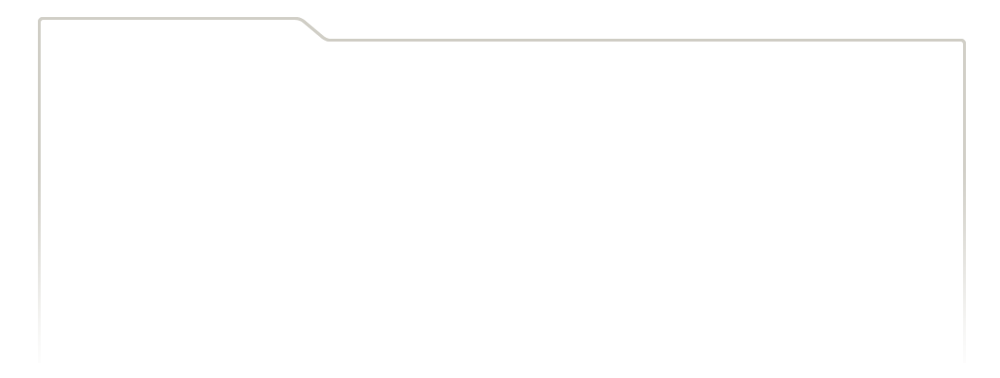
...
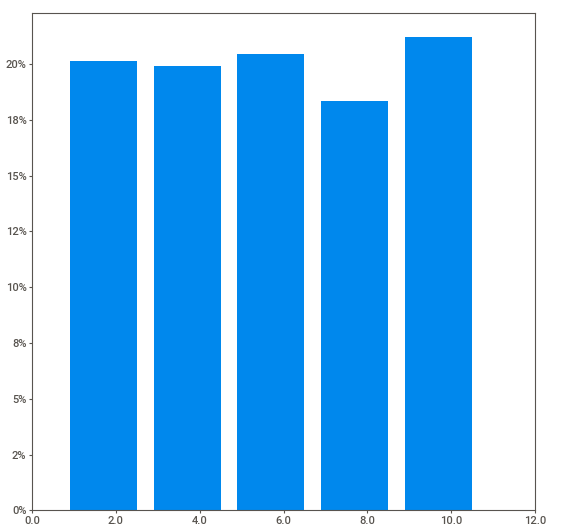
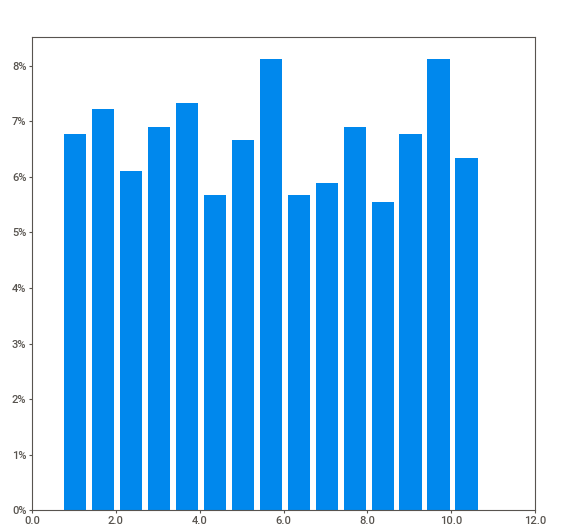
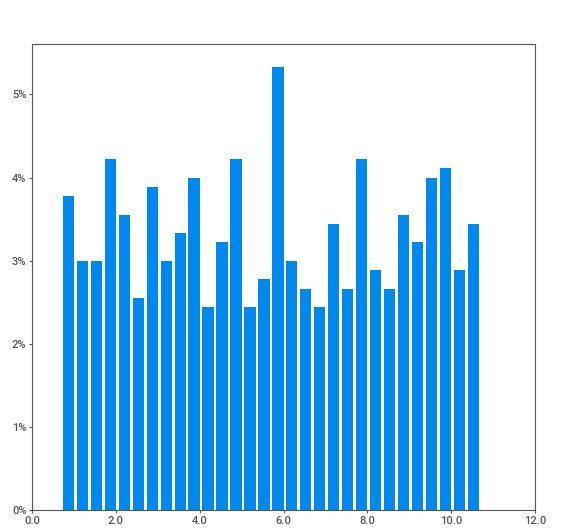
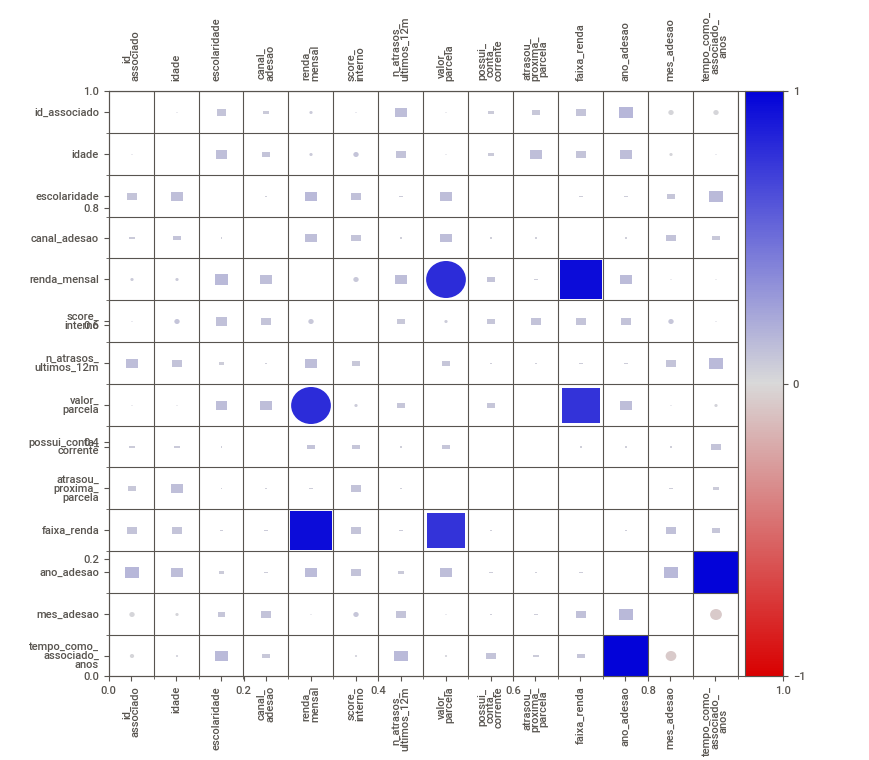
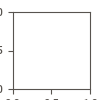

In [42]:
# sweetviz: alternativa, com um layout comparativo diferente
try:
    import sweetviz as sv

    relatorio_sv = sv.analyze(df_tratado)

    # .show_notebook() renderiza o relatório dentro do notebook (Colab/Jupyter)
    relatorio_sv.show_notebook()

except Exception as erro:
    print("Não foi possível gerar o relatório com sweetviz nesta sessão.")
    print("Detalhe do erro (útil para debug):", erro)
    print("Verifiquem a instalação/versão da biblioteca em https://github.com/fbdesignpro/sweetviz")


**Comparando com a análise manual:** ao navegar pelo relatório automático, comparem com o que fizemos manualmente nos Blocos 1-4:
- O relatório provavelmente aponta `renda_mensal` como assimétrica — nós já sabíamos disso e já sabíamos **por quê** (Seção 3.2/3.5) e o que fazer a respeito (Seção 3.7).
- O relatório mostra correlações "cruas" — nós já discutimos a diferença entre Pearson/Spearman e o cuidado de não confundir correlação com causalidade.
- O relatório **não sabe** que `score_interno` tinha um mecanismo MNAR de ausência, nem que decidimos winsorizar em vez de remover — esse raciocínio de negócio só existe porque nós o documentamos.

> 📌 **Importante:** a EDA automatizada é uma **checagem complementar**, ideal para rodar bem no início de um projeto nesta ordem (ela pode até vir *antes* dos Blocos 1-4, como uma primeira triagem) — mas o raciocínio documentado dos blocos anteriores é o que efetivamente sustenta decisões de negócio.

### 5.3 Princípios de Data Storytelling

> 🎯 **Objetivo:** aprender a estrutura de uma comunicação eficaz para um público não-técnico.
>
> 📌 **Por que importa:** a melhor análise do mundo perde valor se a diretoria não conseguir agir a partir dela.
>
> 💡 **Exemplo:** "23% dos associados do App não informam renda" comunica mais do que "taxa de faltantes: 0,23" — mesmo sendo, na prática, o mesmo número.

Transformar achados técnicos em uma narrativa que a diretoria (não-técnica) consiga usar para decidir:

1. **Comece pela resposta, não pelo caminho.** Diretoria quer o "e daí" primeiro; o processo analítico completo é material de apoio, não a abertura.
2. **Um gráfico, uma mensagem.** Se um gráfico precisa de um parágrafo de explicação para ser entendido, provavelmente é o gráfico errado para aquele público.
3. **Números com contexto, não números soltos.** "23% dos associados que entraram pelo App têm renda não informada" comunica mais do que "taxa de faltantes: 0.23".
4. **Termine com uma ação recomendada**, não só com uma observação. "A renda falta mais no canal App" é uma observação; "recomendamos tornar o campo renda obrigatório no formulário do App" é uma ação.

> 🚩 **Armadilha comum:** apresentar significância estatística (p-valores, coeficientes de correlação) como se fosse a mensagem principal para um público de negócio. Esses números sustentam a conclusão nos bastidores — raramente devem ser o destaque central de um slide para a diretoria.
